In [102]:
knitr::opts_chunk$set(echo = TRUE, warning = FALSE,
                      comment = NA,
                      eval = params$correction,
                      message = FALSE,
                      fig.align = "center",
                      out.width = "50%")

ERROR: Error in params$correction: $ operator is invalid for atomic vectors


In [51]:
library(readxl)
library(ggplot2) # pour obtenir des jolis graphiques
library(gridExtra) # pour afficher deux graphiques en même temps
library(evd) # pour ajuster une GEV et POT
library(extRemes) # deuxième librairie pour ajuster une GEV et POT
library(extremogram) # pour faire le graphique de l'extremogram
library(dplyr) # pour la manipulation des données  

# Etude d'une série de températures

Le fichier *TG_STAID011249.txt* donne les températures moyennes
journalières entre 1921 et 2022 à la station météo d'Orly. Les
températures journalières présentent une saisonnalité annuelle et elles
on en moyenne augmenté sur les dernières années. Dans ce TP nous allons
nous intéresser à la partie stationnaire (les résidus) de la série de
températures. L'objectif sera de calculer les niveaux de retour de la
période 100 ans et 200 ans des résidus.

- Décomposer la série en un partie saisonnalité, une partie tendance et
  une partie résiduelle et conserver la partie stationnaire.

- Mettre en place une approche GEV pour l'estimation des niveaux de
  retour annuels.

- Mettre en place une approche POT pour l'estimation des niveaux de
  retour annuels.

- Conclure sur les avantages et désavantages des deux méthodes.

## Préparation des données

1.  Extraire les températures entre le 1er janvier 1950 et le 31
    décembre 2022.


In [52]:
#====================================#
#   Donnees Temperatures Orly    #
TempOrly = read.table("temperature.txt", sep=',', skip=20, head= TRUE) # Extraire les températures 
TempOrly$date = as.Date(as.character(TempOrly$DATE), format = "%Y%m%d") # définir les indices de temps 

2.  Illustrer graphiquement les données.\

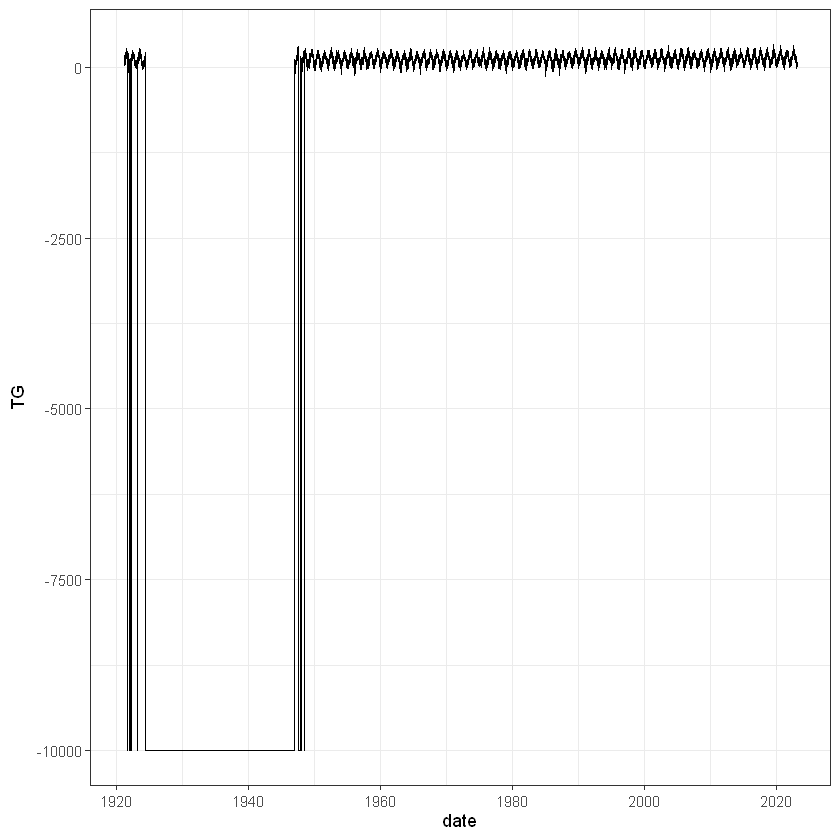

In [53]:
ggplot(TempOrly, aes(x= date, y = TG )) + geom_line() + theme_bw()

3.  Supprimer les 29 février, les NA et la dernière année 2023 qui n'est
    pas complète.

In [54]:
# supprimer les dates en février 
fev29 = c(19520229,19560229,19600229,19640229,19680229,19720229,19760229,19800229,19840229,19880229,19920229,19960229,20000229,20040229,20080229,20120229,20160229,20200229)
# éliminer les NA et l'année 2023
ind1 = which(TempOrly$DATE==19500101) #numéro de la ligne 1950
ind2 = which(TempOrly$DATE==20221231) #numéro de la ligne 2022
# extraire les données qui nous intéressent 
indfev = which(is.element(TempOrly$DATE,fev29))
garde = setdiff(ind1:ind2,indfev) #données entre 1950 et 2022 sauf celles du 29 février
tempe = TempOrly[garde,4]

4.  Illustrer à nouveau graphiquement les données pour contrôler que
    vous avez supprimé tous les NA

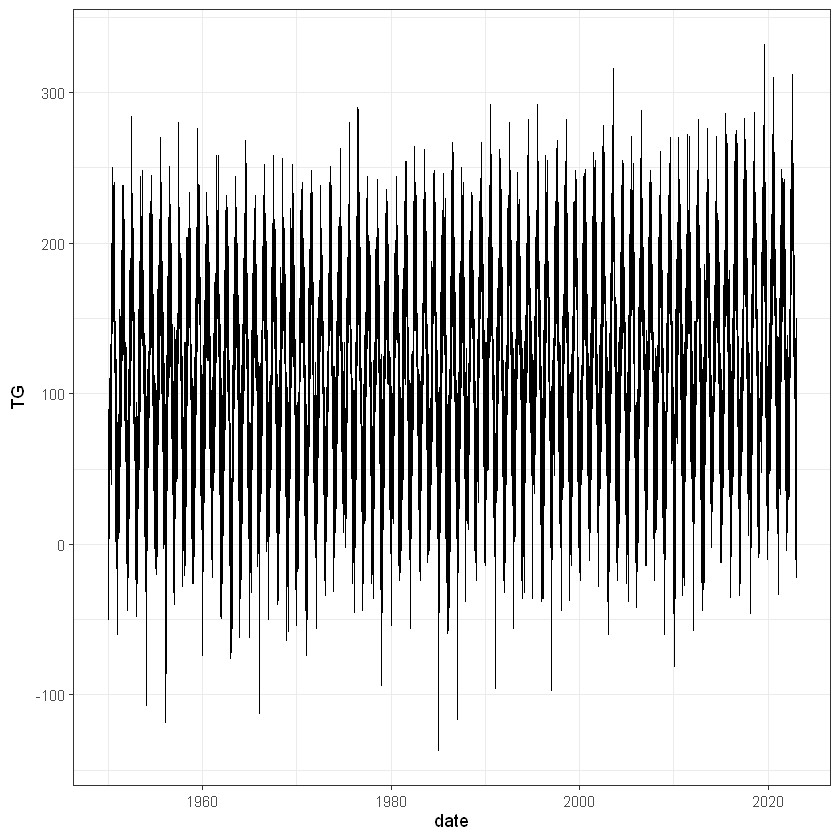

In [55]:
ggplot(TempOrly[garde,], aes(x= date, y = TG )) + geom_line() + theme_bw()

5.  Décomposer la série et conserver la partie stationnaire (les
    résidus). Pour travailler sur des années entières on éliminera la
    première année.

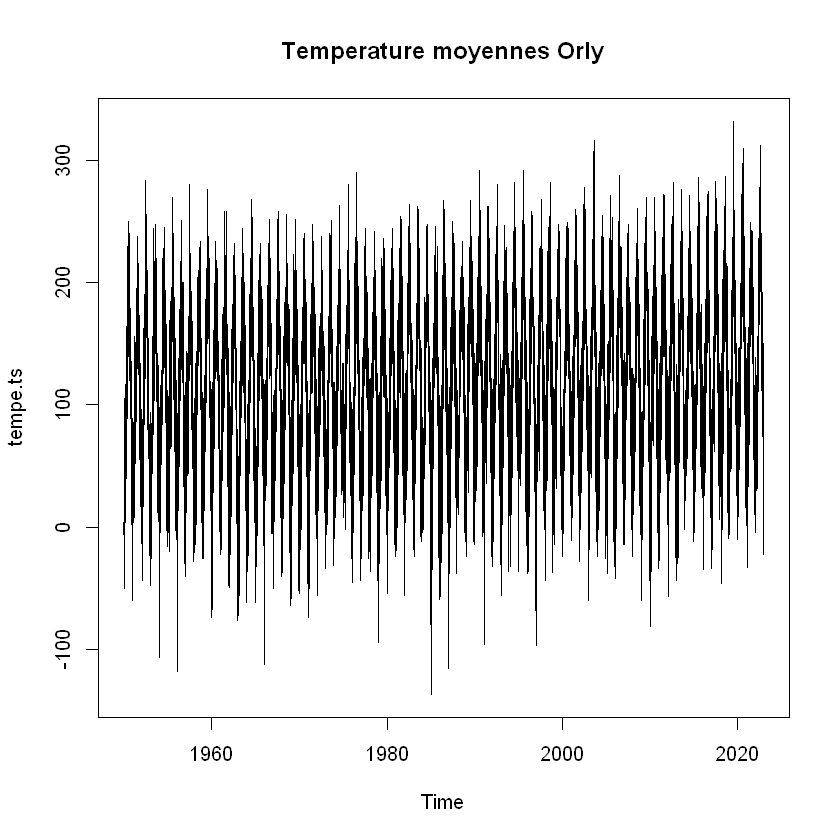

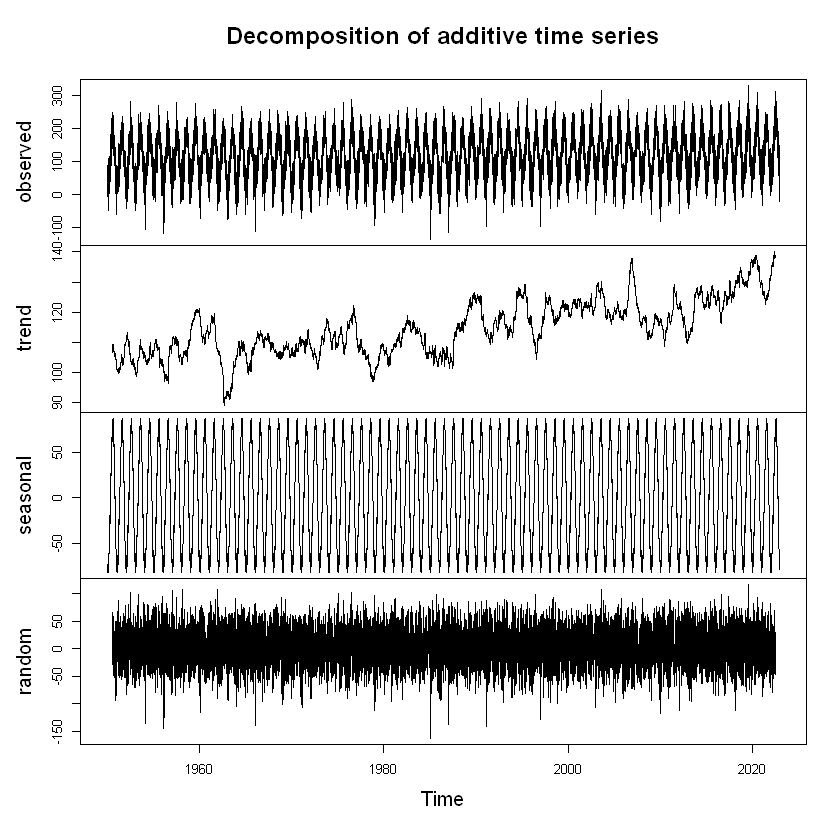

In [56]:
na = 72 # nombre d'années entre janvier 1950 et décembre 2022 
tempe.ts = ts(tempe,start=c(1950,1),frequency=365) # créer un objet série temporelle 
plot(tempe.ts,main='Temperature moyennes Orly') # illustrer graphiquement la série 
tempe.dec = decompose(tempe.ts) # appliquer la décomposition par moyennes mobiles 
plot(tempe.dec) # illustrer graphiquement la décomposition
residus = tempe.dec$random[(365+1):(365*na)] #  supprimer la première année et on récupère les résidus

Soit $Y_1, \dots Y_n$, les variables aléatoires qui modélisent les
résidus stationnaires journaliers de la série des températures. On
souhaite par la suite calculer le niveau de retour du record annuel
$z_N$ associé à la période de retour $N$ ans, c'est à dire la valeur
$z_N$ qui vérifie

$$ \mathbb{P}\Big( \max \{ Y_1,\dots, Y_{365} \} \leq z_N \Big) = 1- \frac{1}{N}.$$

## Approche GEV

1.  Construire des paquets de données de taille `tp` et calculer le
    nombre `P` de paquets par an. Construire la série de maxima par
    paquet.

In [57]:
#max annuel
tp = 365
np = floor(length(residus)/tp) # nombre total de paquets 
P  = 365/tp # nombre d'observation  

matResidus = matrix(residus,tp,np) # 
maxResidus = apply(matResidus,2,max,na, rm=TRUE)

2.  Illustrer graphiquement la série de maxima à l'aide d'une série
    chronologique et d'un histogramme.

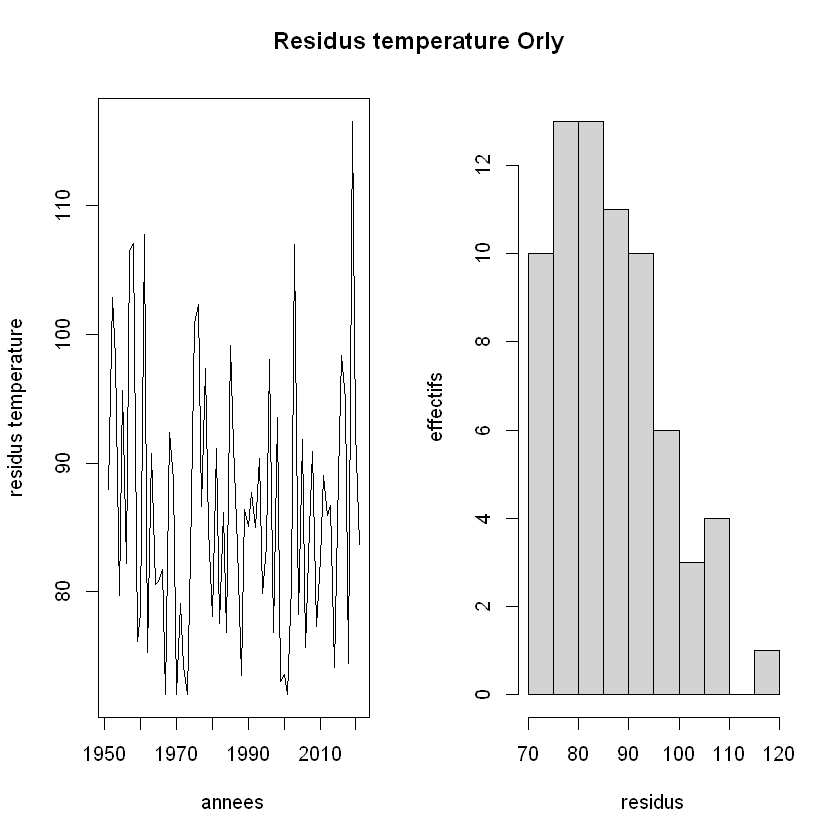

In [58]:
vecAn = 1951:2021
opar = par(mfrow = c(1,2))
plot(vecAn,maxResidus,type='l',xlab='annees',ylab='residus temperature')
hist(maxResidus,main='',xlab='residus',ylab='effectifs')
title(main = 'Residus temperature Orly',outer=TRUE,line=-2)
par(opar)

On remarque sur le graphe de gauche que les maxima annuels sont compris entre 70 et 120. On a quelques années avec un maxima exceptionnellement bas et quelques années avec un maxima exceptionnellement haut (surtout 2021).

Sur le graphe de droite, on a une distribution normalisée : les températures les plus frequentes sont autour de 80-90.

3.  Ajuster une loi des extrêmes généralisée.


Call: fgev(x = maxResidus) 
Deviance: 523.681 

Estimates
      loc      scale      shape  
81.565089   8.179346   0.003939  

Standard Errors
   loc   scale   shape  
1.1532  0.8745  0.1204  

Optimization Information
  Convergence: successful 
  Function Evaluations: 14 
  Gradient Evaluations: 6 


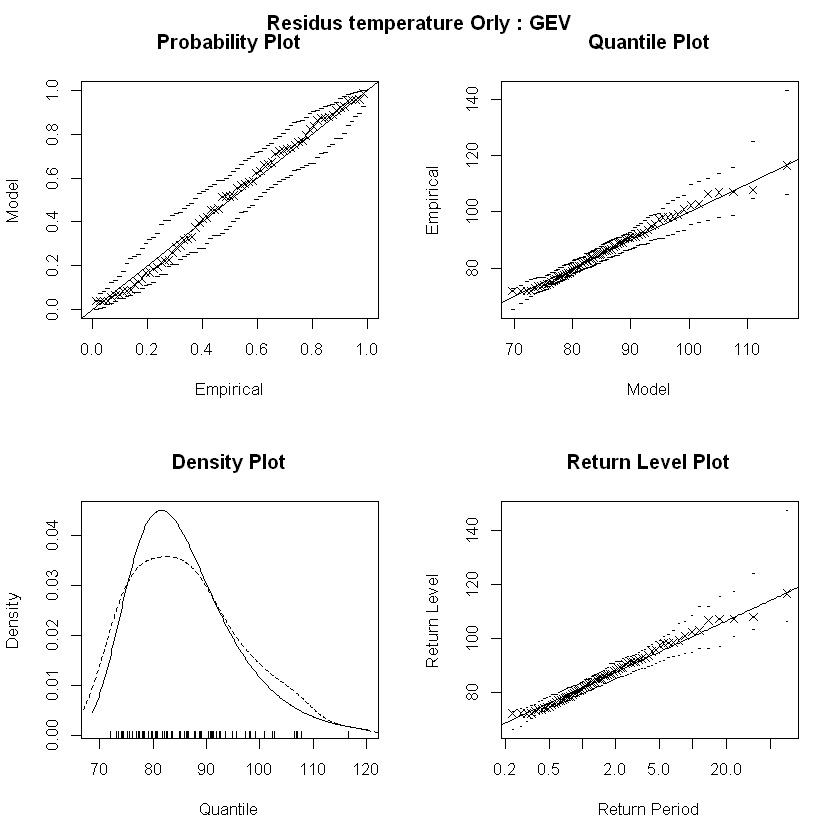

In [59]:
residus.fit=fgev(maxResidus) # utiliser fgev
residus.fit

opar = par(mfrow=c(2,2))
plot(residus.fit) # graphes diagnostiques du modele 
title(main = 'Residus temperature Orly : GEV',outer=TRUE,line=-1.5)
par(opar)

Probability plot : 
Les points sont proches de la droite et ne s'en éloigne pas aux extrêmes. On observe pas de courbe dans le nuage de points.
=> Ajustement global cohérent

Quantile plot : 
Les points sont proches de la droite donc les quantiles observés sont cohérents avec ceux prédits.
=> Ajustement cohérent

Density plot : 
Les deux courbes sont relativement proches avec un écart au sommet donc la concentration des valeurs ou la dispersion peut être mal représentée. 
On a un léger écart dans la queue de droite, donc les valeurs extrêmes peuvent être mal représentées.

Return level plot : 
Les points sont proches de la courbes donc le modèle prédit bien les valeurs extrêmes.

4.  Calculer `q` le record historique de la série des températures et
    déduire la période de retour (en années) associée à ce niveau de
    retour annuel.

In [60]:
q = max(maxResidus)
p= pgev(q,loc = residus.fit$estimate["loc"],
        scale = residus.fit$estimate["scale"],
        shape = residus.fit$estimate["shape"],
        lower.tail = FALSE) # utiliser pgev 
Periode = 1/(p)
Periode ## 

shape 
70.09302

Période = 70,1 ans

5.  Estimer les paramètres et en déduire un niveau de retour à 100 et
    200 ans.

[1] "profiling quantile"
[1] "profiling quantile"


,2.5 %,97.5 %
quantile,101.7531824,137.066552
scale,6.4648041,9.893760
shape,-0.2323794,0.237349


,lower,upper
quantile,108.9703,155.4543


,2.5 %,97.5 %
quantile,101.4665143,148.853800
scale,6.4650387,9.895884
shape,-0.2328178,0.237483


,lower,upper
quantile,111.8611,176.9325


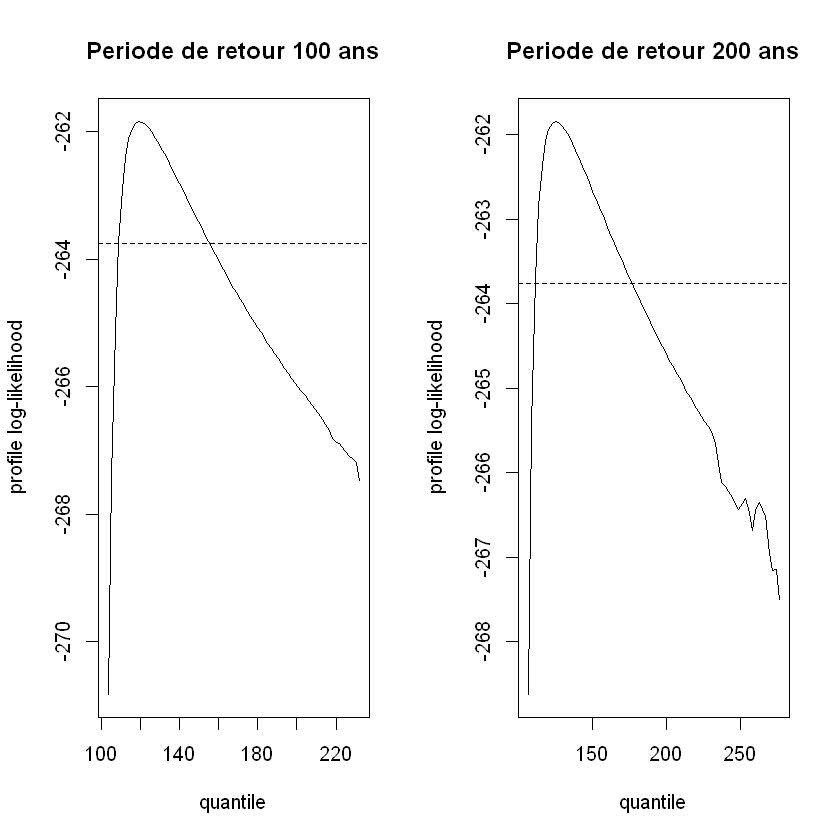

In [61]:
ProbDep2 = 1/200  # definir la proba qui nous interesse
ProbDep1 = 1/100   

residus.qfit1 = fgev(maxResidus,prob=ProbDep1)
residus.qdev.prof1 = profile(residus.qfit1,which="quantile")

residus.qfit2 = fgev(maxResidus,prob=ProbDep2)
residus.qdev.prof2 = profile(residus.qfit2,which="quantile")

opar = par(mfrow=c(1,2))
residus.qPCI1 =plot(residus.qdev.prof1,
                                main='Periode de retour 100 ans')
residus.qPCI2 = plot(residus.qdev.prof2,
                                 main='Periode de retour 200 ans')

par(opar)

confint(residus.qfit1)

confint(residus.qdev.prof1)


confint(residus.qfit2)


confint(residus.qdev.prof2)

Que pouvez-vous conclure des intervalles de confiance ?

Pour residus.qfit1, on a shape [-0.23,0.24] donc le signe du paramètre de forme est incertain car l'intervalle contient zéro.

L'incertitude est importante car elle recoupe plusieurs dizaines.

Courbe "Periode de retour de 100 ans" : 
Le maximum est atteint pour un quantile autour de 120-125 et décroit ensuite.Donc les valeurs proches de ce maximum sont mieux soutenues par les données. 
La ligne en pointillé (seuil en dessous duquel les valeurs du quantile ne sont plus considérées comme compatibles avec les données au niveau de confiance chois, 95 % ici) recoupe une première fois la courbe vers 115 (borne basse) et une deuxième fois vers 150 (borne haute) donc l'incertitude est relativement élevée pour les valeurs extrêmes. 

Courbe "Periode de retour de 200 ans" :
Le maximum est atteint pour un quantile autour de 135 et décroit (plus fort que pour une période de retour de 100 ans) ensuite. 
On remarque des irrégularités sur la droite de la courbe, donc les valeurs extrêmes sont surement mal représentées. 
L'incertitude parait aussi relativement élevée.

### Taille de paquet differente

Soit $Y_1, \dots Y_n$, les variables aléatoires qui modélisent les
résidus stationnaires journaliers de la série des températures. On
souhaite par la suite calculer le niveau de retour journalier $z_N$
associé à la période de retour $N$ ans, c'est à dire la valeur $z_N$ qui
vérifie

$$ \mathbb{P}\Big( Y_1 \leq z_N \Big) = 1- \frac{1}{N*P}.$$
avec $P$ qui correspond au nombre d'observations journalières par an.

1.  Afficher la série chronologique et l'histogramme des données
    journalières.

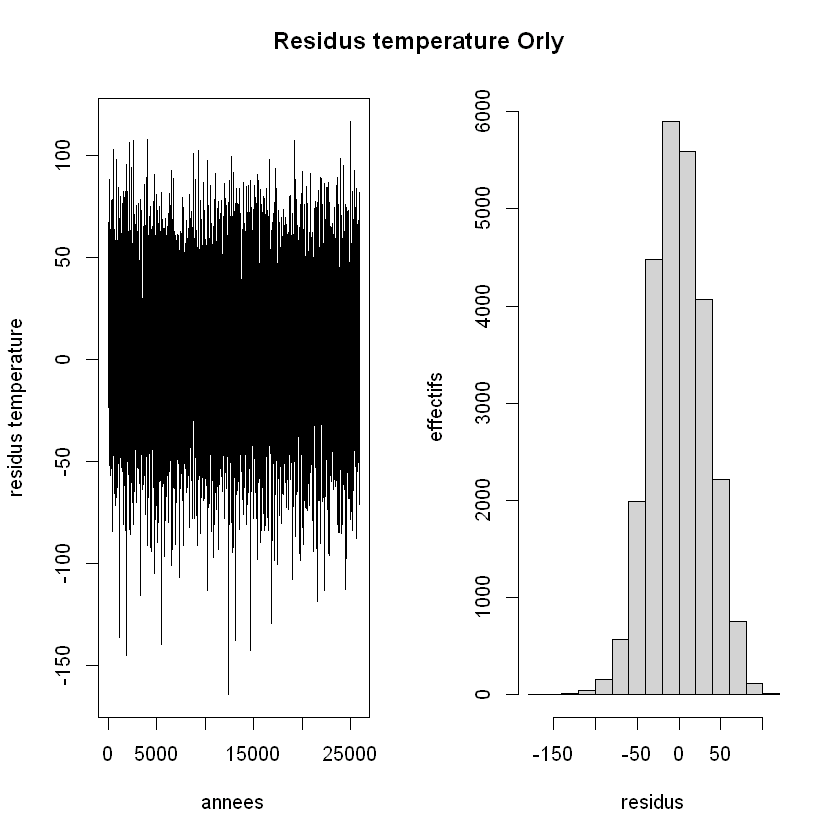

In [62]:
#max annuel
tp = 1
np = floor(length(residus)/tp)
P  = 365/tp # nombre d'observation  

matResidus = matrix(residus[1:np],tp,np) # 
maxResidus = apply(matResidus,2,max)

opar = par(mfrow = c(1,2))
plot(maxResidus,type='l',xlab='annees',ylab='residus temperature')
hist(maxResidus,main='',xlab='residus',ylab='effectifs')

title(main = 'Residus temperature Orly',outer=TRUE,line=-2)

par (opar)

Les résidus ont une distribution normalisée autour de 0 avec quelques valeurs extrêmes, surtout dans le négatif vers -150.

2.  Vérifier l'hypothèse des observations iid

[1] 1.0000000 0.5133153 0.3200772 0.2491309 0.2117465 0.1762659 0.1577116
 [8] 0.1426363 0.1291071 0.1302667 0.1283340 0.1233089

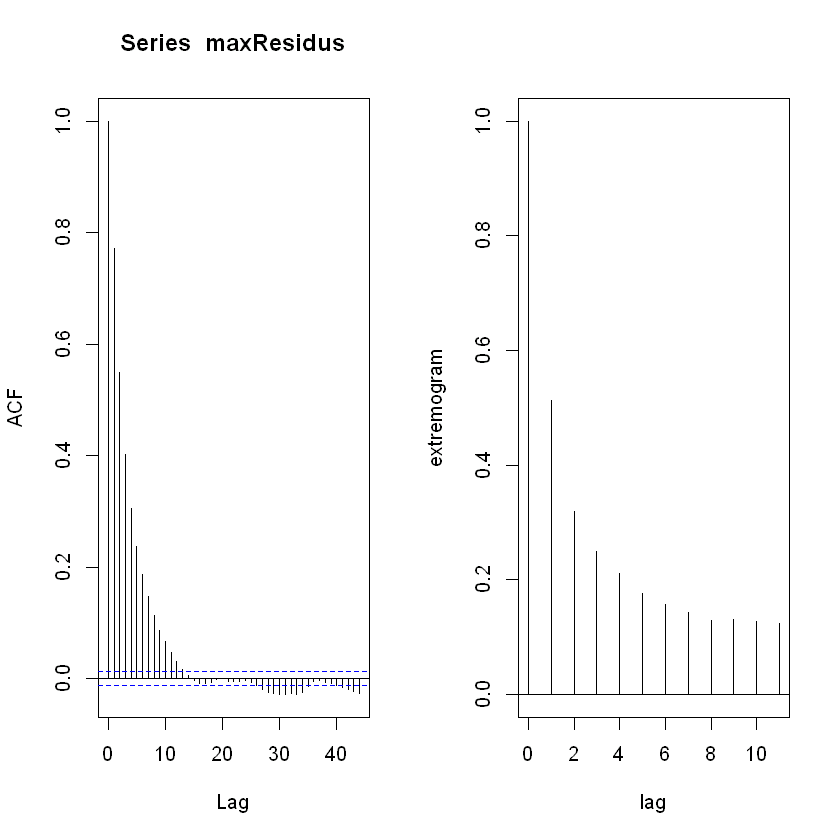

In [63]:
par(mfrow=c(1,2))
acf(maxResidus)
extremogram1(maxResidus,quant = .9, maxlag=12 , type = 1)

Pour les deux graphes, pour lag = 1, on a une autocorrélation forte (autant pour l'ensemble des valeurs que pour uniquement les valeurs extrêmes) qui diminue progressivement mais qui reste quand même importante. Donc on a une dépendance temporelle forte des valeurs entre elles, et des valeurs extrêmes entre elles.

**On remarque que si cette hypothèse d'indépendance n'est par vérifiée
alors il faudra calculer l'indice de clustering** $\theta$ de la série
afin de conclure.

En effet,

$$\begin{align*}
 \mathbb{P}\Big( Y_1 \leq z_N \Big) 
  &\approx \mathbb{P}\Big( \max \{ Y_1,\dots, Y_{m} \} \leq z_N \Big)^{1/(\theta m)}
 \end{align*}$$
avec $m$ une taille de paquet quelconque.

Donc, il suffit de trouver $z_N$ tel que

$$\mathbb{P}\Big( \max \{ Y_1,\dots, Y_{m} \} \leq z_N \Big)^{1/(\theta m)} = 1- \frac{1}{N*P}.$$
avec $P$ qui correspond au nombre d'observations du maxima par an.

3.  Utiliser une taille de paquet `tp` = 5 (et ensuite `tp` = 73) et
    calculer les maxima par parquets. Afficher la série chronologique et
    l'histogramme des la série de records par paquets.

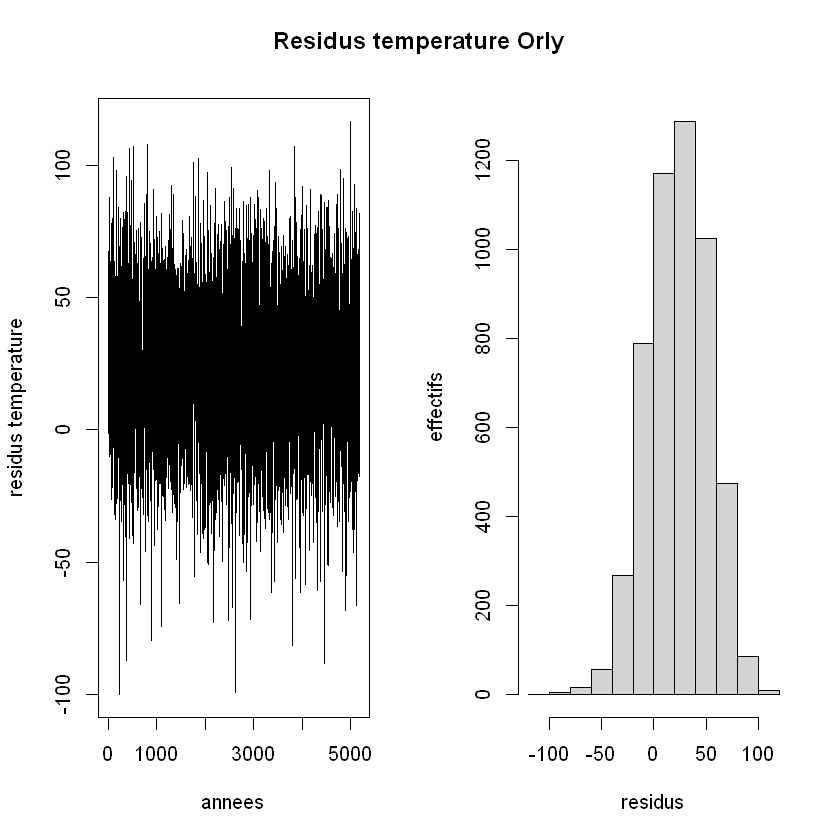

In [64]:
#max annuel
tp = 5
np = floor(length(residus)/tp)
P  = 365/tp # nombre d'observation  

matResidus = matrix(residus[1:(np*tp)],tp,np) # 
maxResidus = apply(matResidus,2,max)

opar = par(mfrow = c(1,2))
plot(maxResidus,type='l',xlab='annees',ylab='residus temperature')
hist(maxResidus,main='',xlab='residus',ylab='effectifs')

title(main = 'Residus temperature Orly',outer=TRUE,line=-2)

Les paquets de 5 valeurs sont distribués normalement autour de 40-50.

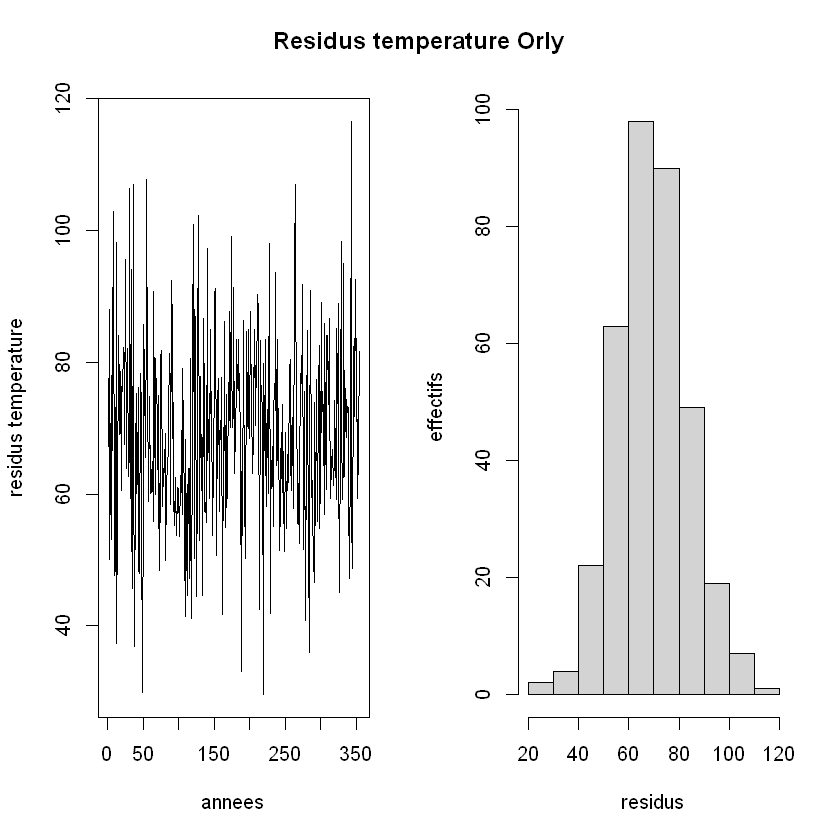

In [65]:
#max annuel
tp = 73
np = floor(length(residus)/tp)
P  = 365/tp # nombre d'observation  

matResidus = matrix(residus[1:(np*tp)],tp,np) # 
maxResidus = apply(matResidus,2,max)

opar = par(mfrow = c(1,2))
plot(maxResidus,type='l',xlab='annees',ylab='residus temperature')
hist(maxResidus,main='',xlab='residus',ylab='effectifs')

title(main = 'Residus temperature Orly',outer=TRUE,line=-2)

Les paquets de 73 valeurs sont distribués autour de 70.

In [66]:
par(opar)

4.  Vérifier que les maxima par paquets sont indépendants.

[1] 1.00000000 0.13888889 0.11111111 0.02777778 0.11111111 0.05555556
 [7] 0.08333333 0.02857143 0.05714286 0.02857143 0.14285714 0.17142857

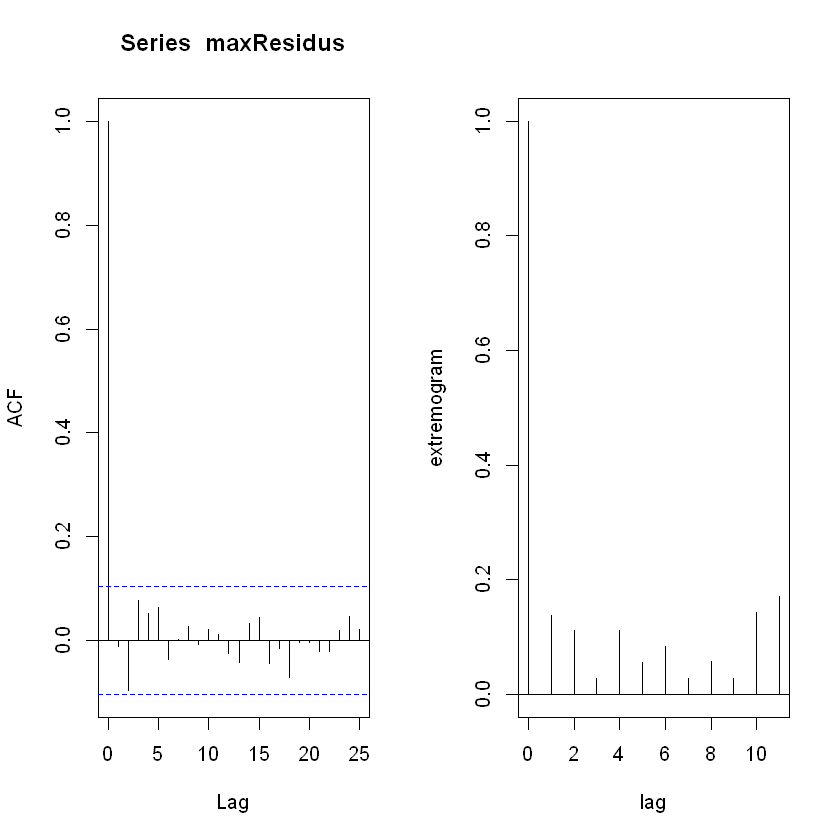

In [67]:
par(mfrow=c(1,2))
acf(maxResidus)
extremogram1(maxResidus,quant = .9, maxlag=12 , type = 1)

Comme le graphe d'avant, on a une autocorrélation forte pour lag = 1, mais, cette fois-ci, elle décroit très rapidement autant pour l'ensemble des valeurs que pour les valeurs extrêmes. Donc les valeurs, et les valeurs extrêmes, sont indépendantes temporrellement ici. 

5.  Ajuster une loi des extrêmes généralisée.


Call: fgev(x = maxResidus) 
Deviance: 2895.311 

Estimates
    loc    scale    shape  
63.6781  13.8886  -0.2143  

Standard Errors
   loc   scale   shape  
0.7995  0.5445  0.0260  

Optimization Information
  Convergence: successful 
  Function Evaluations: 33 
  Gradient Evaluations: 12 


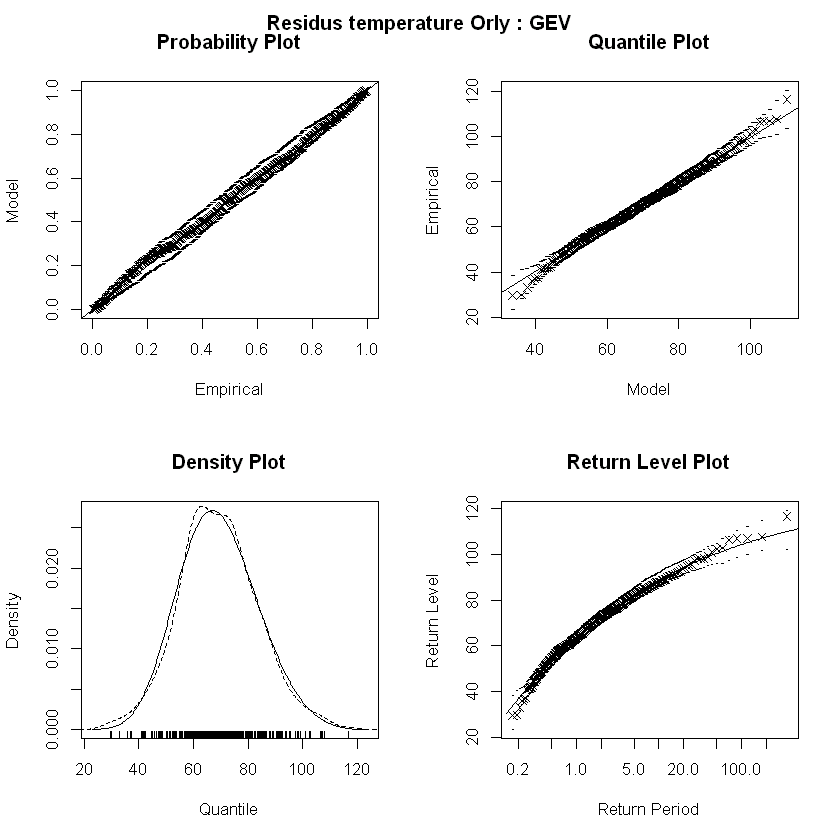

In [68]:
# Approche GEV
#=============
residus.fit=fgev(maxResidus)
residus.fit

opar = par(mfrow=c(2,2))
plot(residus.fit)
title(main = 'Residus temperature Orly : GEV',outer=TRUE,line=-1.5)

par(opar)

Probability plot : 
Les points sont proches de la droite et ne s'en éloigne pas aux extrêmes. On observe pas de courbe dans le nuage de points.
=> Ajustement global cohérent

Quantile plot : 
Les points sont proches de la droite donc les quantiles observés sont cohérents avec ceux prédits.
=> Ajustement cohérent

Density plot : 
Les deux courbes sont relativement proches sans un écart au sommet donc la concentration des valeurs ou la dispersion est bien représentée. 
Même dans la queue de droite, les valeurs extrêmes sont proches du modèles donc elles sont bien représentées.

Return level plot : 
Les points sont proches de la courbes donc le modèle prédit bien les valeurs extrêmes.

6.  Estimer les paramètres et en déduire un niveau de retour à 100 et
    200 ans lorsque l'indice extremal de résidus vaut $\theta = 0.5$. On
    calculera ce dernier à continuation.

[1] "profiling quantile"
[1] "profiling quantile"


,2.5 %,97.5 %
quantile,112.5800062,128.5636722
scale,12.8225447,14.9571287
shape,-0.2652506,-0.1634113


,lower,upper
quantile,114.9262,131.5715


,2.5 %,97.5 %
quantile,113.1817647,130.1414737
scale,12.8211184,14.9548805
shape,-0.2651986,-0.1634107


,lower,upper
quantile,115.7125,133.4271


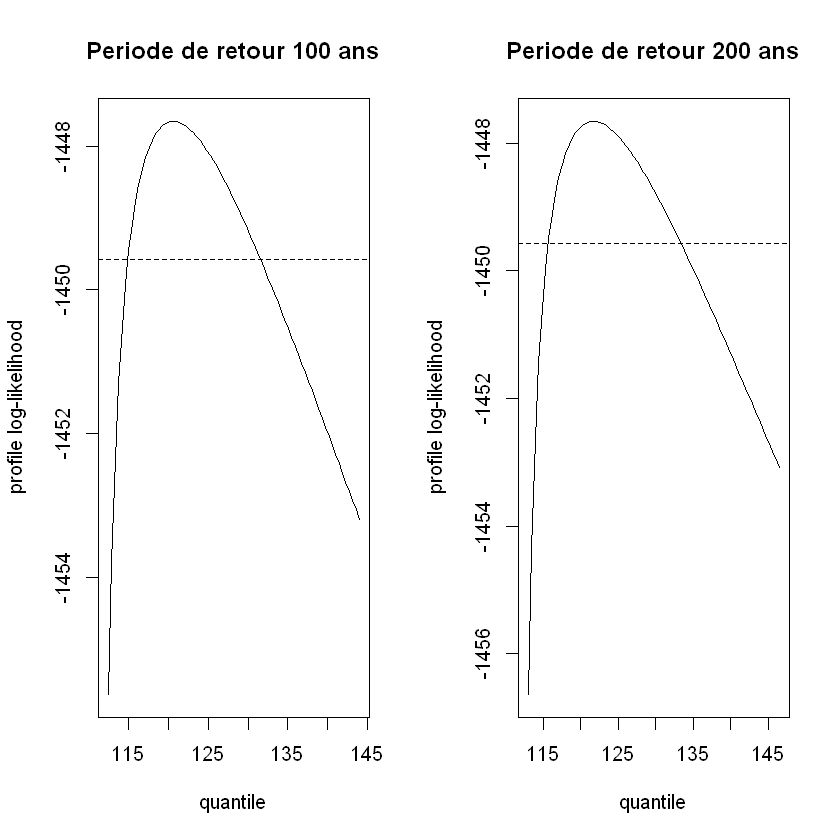

In [69]:
theta = 0.5
P = 365
ProbDep2 = (1/theta)*1/(200*P)  # definir la proba qui nous interesse
ProbDep1 = (1/theta)*1/(100*P)   

residus.qfit1 = fgev(maxResidus,prob=ProbDep1)
residus.qdev.prof1 = profile(residus.qfit1,which="quantile")

residus.qfit2 = fgev(maxResidus,prob=ProbDep2)
residus.qdev.prof2 = profile(residus.qfit2,which="quantile")

opar = par(mfrow=c(1,2))
residus.qPCI1 =plot(residus.qdev.prof1,
                                main='Periode de retour 100 ans')
residus.qPCI2 = plot(residus.qdev.prof2,
                                 main='Periode de retour 200 ans')

par(opar)

confint(residus.qfit1)

confint(residus.qdev.prof1)

confint(residus.qfit2)

confint(residus.qdev.prof2)

Les intervalles [lowest, upper] sont plus réduits et se chevauchent entre qfit1 et qfit2. Les shape (paramètre de forme) de qfit1 et qfit2 sont négatifs donc la distribution ajustée appartient au domaine de Weibull.

Par rapport au modèle précédent, pour la période de retour à 200 ans, les valeurs extrêmes sont régulières.

## Approche POT

On propose à continuation une deuxième approche pour calculer le niveau
de retour journalier $z_N$ associé à la période de retour 100 ans et 200
ans.
$$ \mathbb{P}\Big( Y_1 \leq z_N \Big) = 1- \frac{1}{N*P}.$$

On implémente à continuation la méthode POT.

1.  Déterminer le seuil et visualiser les dépassements.

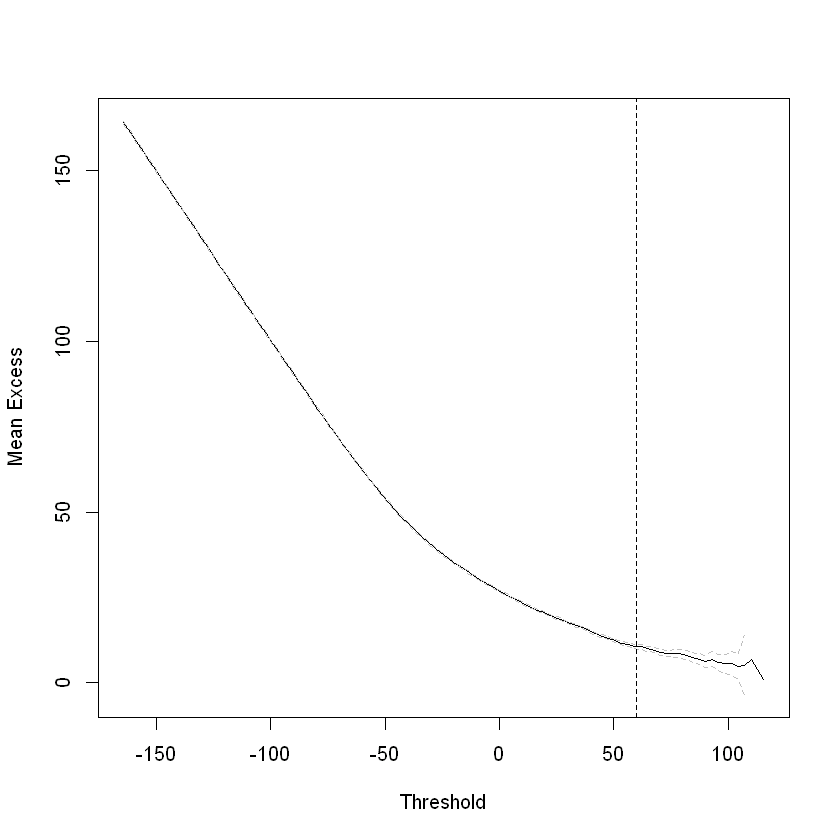

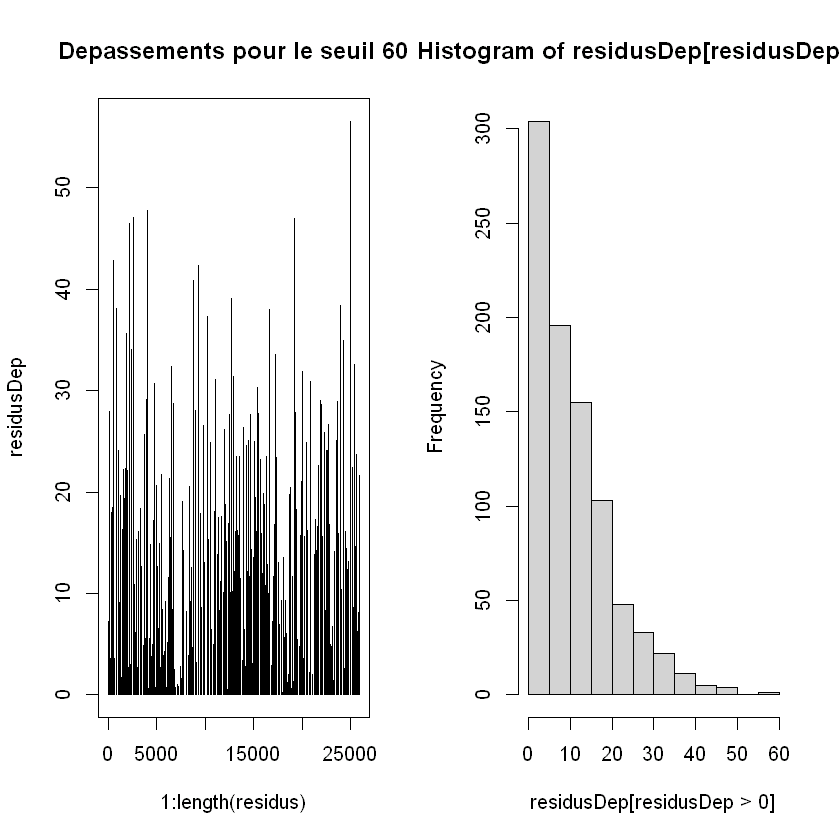

In [70]:
# Approche GPD
#=============
mrlplot(residus)
seuil = 60 
abline(v=seuil,lty=2)

opar = par(mfrow = c(1,2))
residusDep = residus-seuil
residusDep[residusDep<0]=NA
plot(1:length(residus),residusDep,type='h',
     main=paste('Depassements pour le seuil',seuil))
hist(residusDep[residusDep>0])
par(opar)

On voit que la pente de la courbe ralentie à partir de 0 et que les valeurs deviennent irrégulire après de 60. Donc on peut prendre un seuil entre 30 et 60.

Lorsqu'on visualise les dépassements, on remarque que la majorité des résidu-seuil est comprise entre 0 et 5. Plus résidu-seuil augmente, plus la fréquence de dépassement du seuil diminue.On observe toutefois quelques valeurs extrêmes avec des résidus-seuil > 40.

2.  Ajuster aux dépassement de seuil une loi GPD. Utiliser des
    graphiques diagnostiques pour évaluer la qualité de l'ajustement
    obtenu.


Call: fpot(x = residus, threshold = seuil, npp = 365) 
Deviance: 5905.042 

Threshold: 60 
Number Above: 882 
Proportion Above: 0.034 

Estimates
scale  shape  
12.15  -0.15  

Standard Errors
  scale    shape  
0.53623  0.02899  

Optimization Information
  Convergence: successful 
  Function Evaluations: 18 
  Gradient Evaluations: 6 


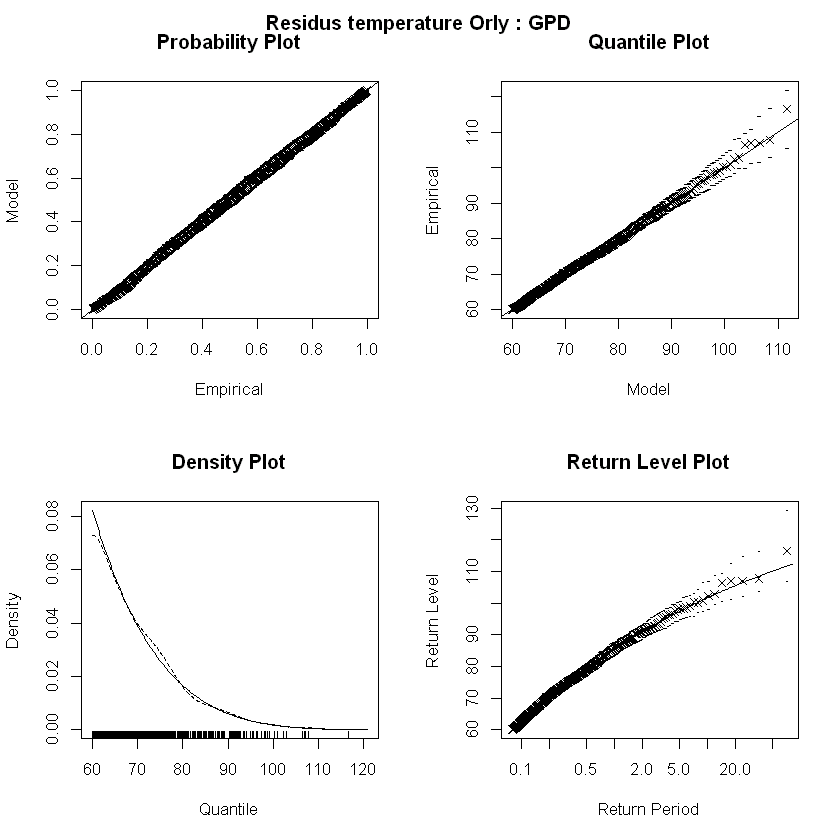

In [71]:
residus.gpd=fpot(residus,seuil,npp=365) 
residus.gpd
opar = par(mfrow=c(2,2))
plot(residus.gpd)
title(main = 'Residus temperature Orly : GPD',outer=TRUE,line=-1.5)
par(opar)

Probability plot : 
Les points sont proches de la droite et ne s'en éloigne pas aux extrêmes. On observe pas de courbe dans le nuage de points.
=> Ajustement global cohérent

Quantile plot : 
Les points sont proches de la droite donc les quantiles observés sont cohérents avec ceux prédits.
=> Ajustement cohérent

Density plot : 
Les deux courbes sont proches et se chevauchent presque. 
Même dans la queue de droite, les valeurs extrêmes sont proches du modèles donc elles sont bien représentées.

Return level plot : 
Les points sont proches de la courbes donc le modèle prédit bien les valeurs extrêmes.

3.  Estimer les paramètres et en déduire un niveau de retour à 100 et
    200 ans.

[1] "profiling rlevel"
[1] "profiling rlevel"


,2.5 %,97.5 %
rlevel,107.0704729,119.20263645
shape,-0.2071579,-0.09381218


,lower,upper
rlevel,108.409,121.014


,2.5 %,97.5 %
rlevel,108.7891237,122.31995678
shape,-0.2086246,-0.09744797


,lower,upper
rlevel,110.4739,125.0987


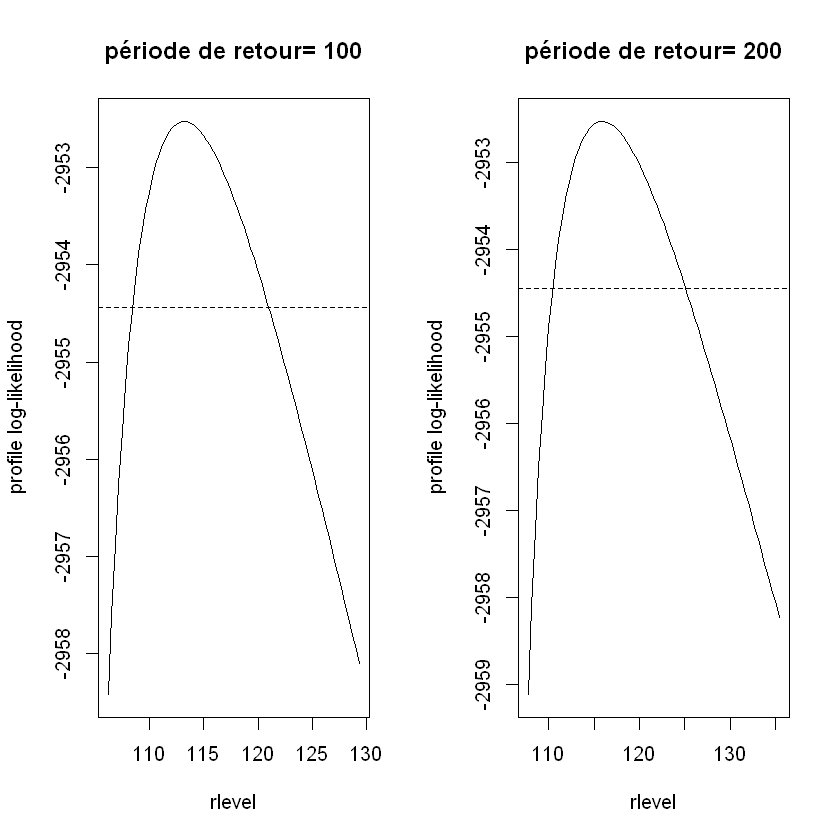

In [72]:
Pretour1 = 100
Pretour2 = 200
residus.q1 = fpot(residus,seuil,npp=365,mper=Pretour1)
residus.dev.qprof1 = profile(residus.q1,which='rlevel') 

residus.q2 = fpot(residus,seuil,npp=365,mper=Pretour2) 
residus.dev.qprof2 = profile(residus.q2,which='rlevel')

opar = par(mfrow=c(1,2))
residus.dev.qPIC1 = plot(residus.dev.qprof1,main=paste('période de retour=',Pretour1))
residus.dev.qPIC2 = plot(residus.dev.qprof2,main=paste('période de retour=',Pretour2))

par(opar)

confint(residus.q1)

confint(residus.dev.qprof1)

confint(residus.q2)

confint(residus.dev.qprof2)

Les intervalles [lowest, upper] sont relativement petits et se chevauchent entre qfit1 et qfit2. Les shape (paramètre de forme) de qfit1 et qfit2 sont négatifs donc la distribution ajustée appartient au domaine de Weibull.



 Data span  70.94867 years 
Setting up parameter model design matrices.
Parameter model design matrices set up.
Using Lmoments estimates as initial estimates.  Initial value = 2952.529 
Initial estimates are:
     scale      shape 
12.1188678 -0.1467806 
Beginning estimation procedure.
initial  value 2952.528737 
final  value 2952.521003 
converged
Time difference of 0.03563213 secs

 Preparing to calculate  95 % CI for  200-year return level 

 Model is   fixed 

 Using Profile Likelihood Method.

 Calculating profile likelihood.  This may take a few moments.

 Profile likelihood has been calculated.  Now, trying to find where it crosses the critical value =  -2954.442 


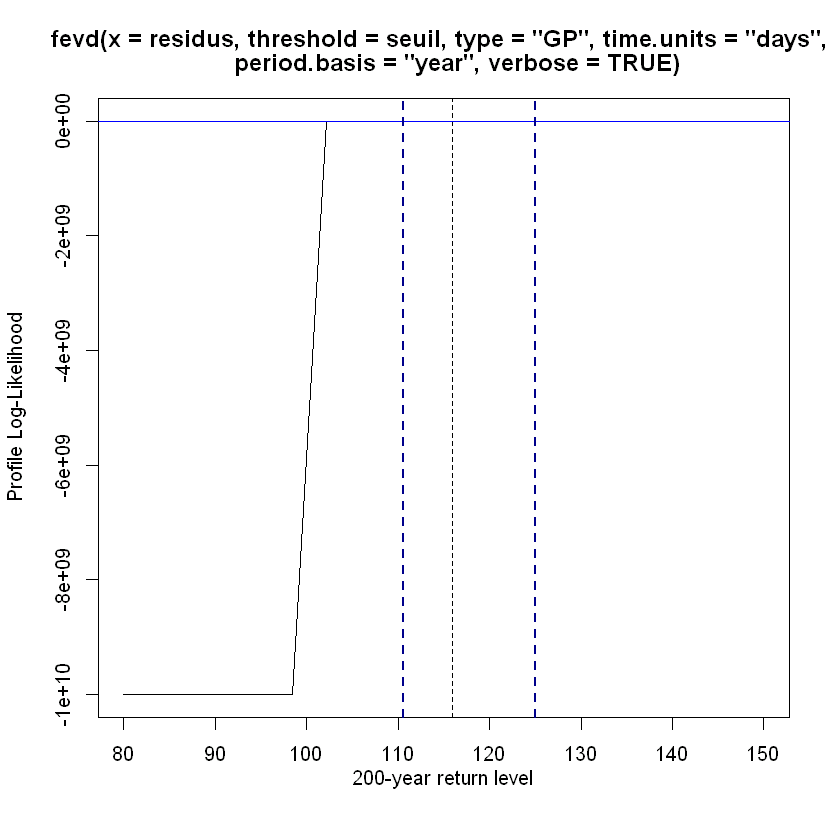

In [73]:
# Une alternative avec le package extRemes 
library(extRemes)
fit <- fevd(residus,
              threshold = seuil, 
              time.units = "days",
              period.basis = "year",
              type = "GP", 
              verbose = TRUE)


ci_proflik <- ci(fit, type = "return.level", method = "proflik", return.period = Pretour2, verbose = T, xrange = c(80,150))


4.  Vérifier l'hypothèse des observations iid

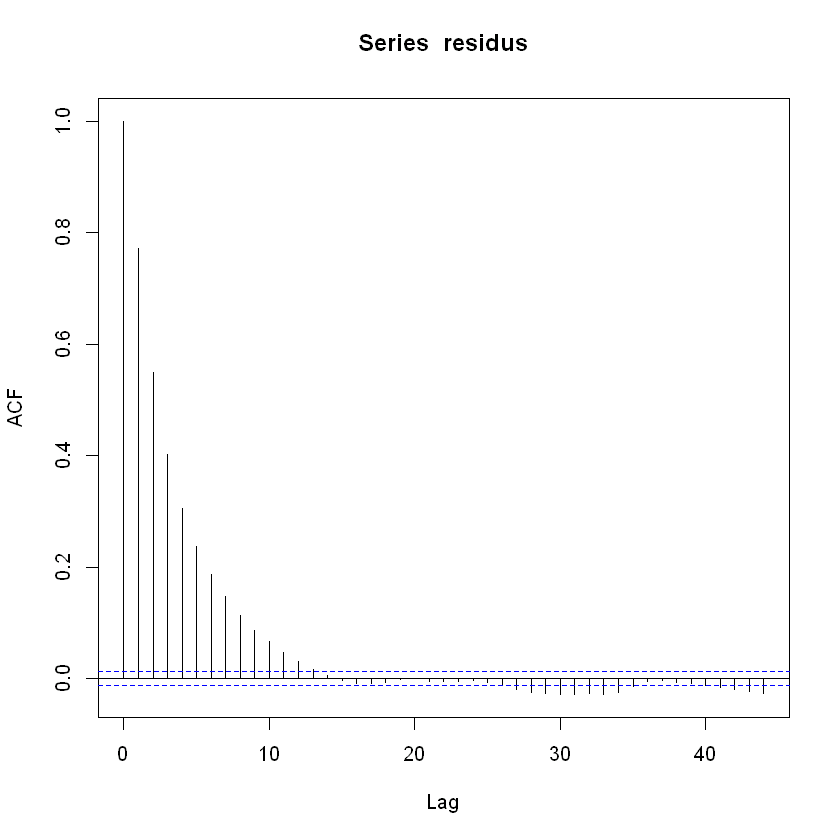

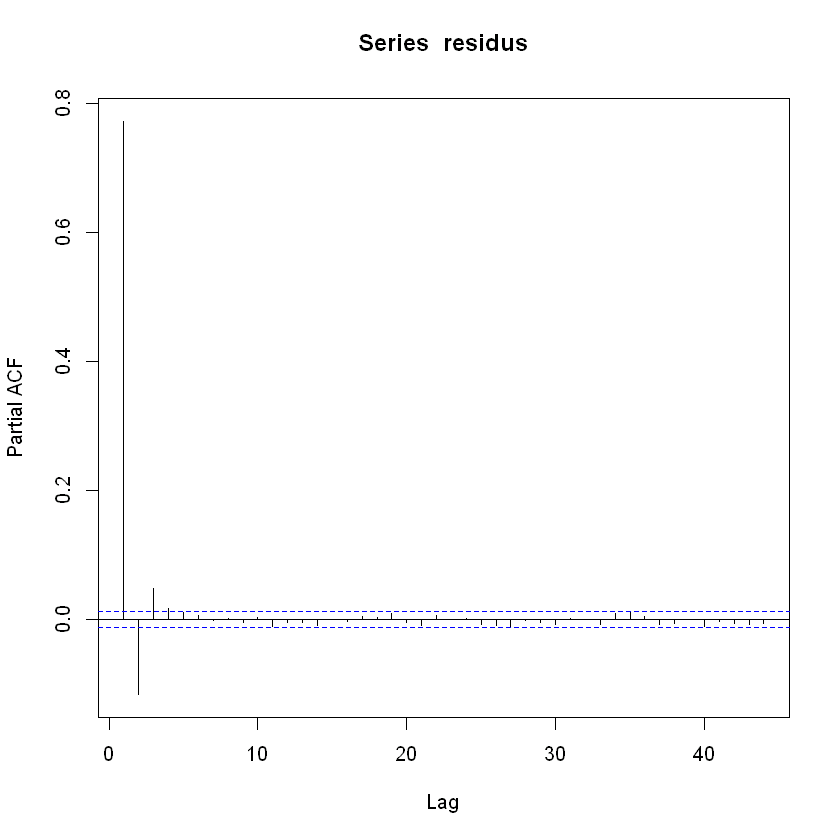

[1] 1.00000000 0.39115646 0.20658343 0.14090909 0.11250000 0.08295455
 [7] 0.07159091 0.05454545 0.05227273 0.04545455 0.05000000 0.05340909
[13] 0.04886364 0.04545455 0.04545455 0.03977273 0.03636364 0.03181818
[19] 0.03977273 0.03863636 0.03636364 0.03409091 0.03295455 0.03863636
[25] 0.03295455 0.03181818 0.03750000 0.03522727 0.03522727 0.02727273

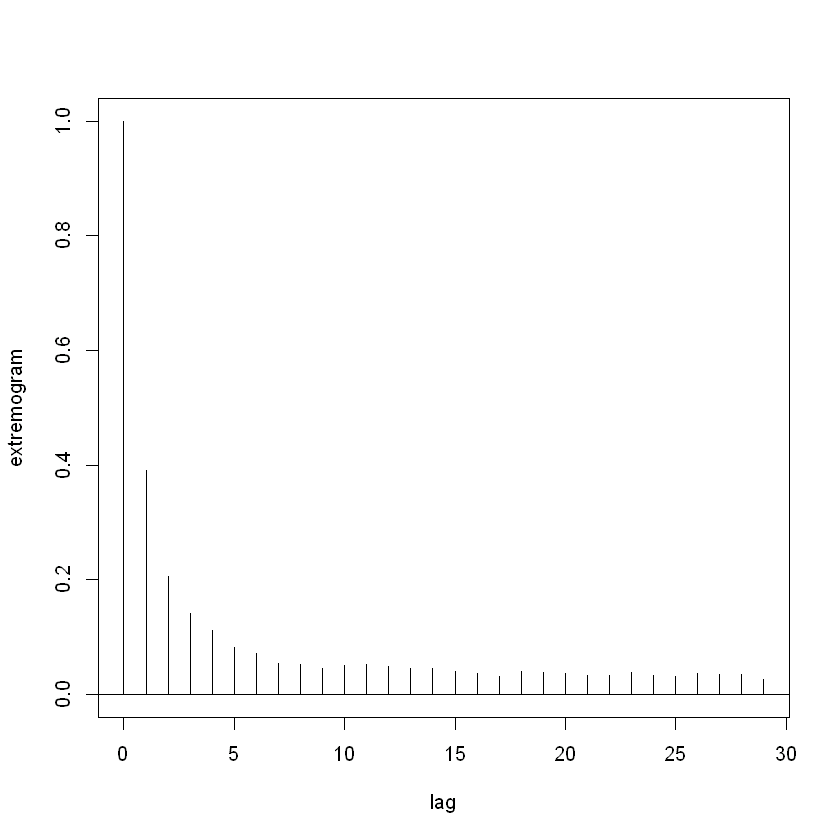

In [74]:
par(mfrow=c(1,1))
acf(residus)
pacf(residus)
extremogram1(residus,quant = sum(residus<=seuil)/length(residus), maxlag=30 , type = 1)

Quand on regarde l'extremogramme, on voit que pour lag = 1, l'autocorrélation est forte puis diminue brusquement ensuite. Donc les variables sont indépendantes.

5.  Calculer l'indice extremal de clustering

In [75]:

# Approche clusters
#==================
separ = 5
clusters   = clusters(residus,seuil,r=separ)
residus.q1 = fpot(residus,seuil,npp=365, r=separ, cmax=TRUE)
theta = length(clusters)/sum(residus>seuil)
theta 

[1] 0.4954649

On obtient teta = 0,50
=> On a un regroupement notable, les événements tendent à se reproduire en épisodes plutôt que de manière isolée.

6.  Ré-estimer les paramètres et les niveaux de retour à 100 et 200 ans
    et comparer avec l'approche indépendante.


 Data span  1.193703 years 
Setting up parameter model design matrices.
Parameter model design matrices set up.
Using Lmoments estimates as initial estimates.  Initial value = 669.8166 
Initial estimates are:
     scale      shape 
12.9285912 -0.2157394 
Beginning estimation procedure.
initial  value 669.816637 
final  value 669.683012 
converged
Time difference of 0.005512953 secs

 Preparing to calculate  95 % CI for  200-year return level 

 Model is   fixed 

 Using Profile Likelihood Method.

 Calculating profile likelihood.  This may take a few moments.

 Profile likelihood has been calculated.  Now, trying to find where it crosses the critical value =  -671.6037 


fevd(x = resid_clustr, threshold = seuil, type = "GP", time.units = "days", 
    period.basis = "year", verbose = TRUE)

[1] "Profile Likelihood"

[1] "200-year return level: 117.7"

[1] "95% Confidence Interval: (111.5789, 151.854)"


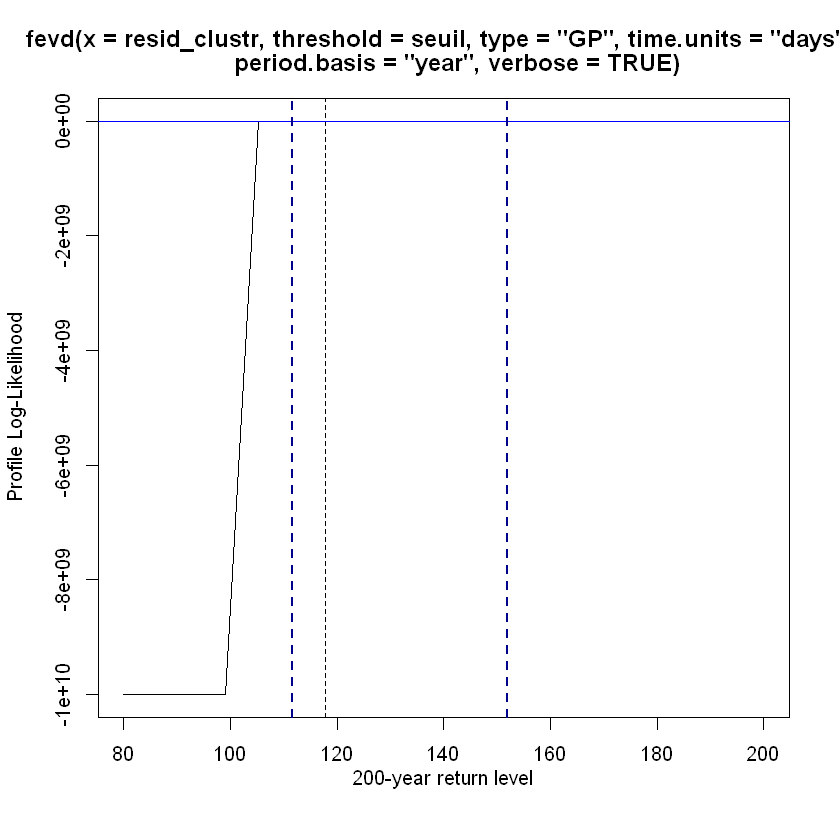

In [76]:
## approche GPD 
set.seed(12)
resid_clustr <- sapply(1:length(clusters), function(k) sample(clusters[[k]], 1) ) # sample clusters 
fit <- fevd(resid_clustr,
              threshold = seuil, 
              time.units = "days",
              period.basis = "year",
              type = "GP", 
              verbose = TRUE)

ci_proflik <- ci(fit, type = "return.level", method = "proflik", return.period = Pretour2, verbose = T, xrange = c(80,200))

ci_proflik


# Etude d'une série de débit

## Préparation des données

1.  Extraire les débits entre le 24 janvier 1983 et le 9 septembre 2024

In [77]:
#====================================#
#   Donnees Débit Yvette    #
debitYvette = read_excel("DebitYvette.xlsx") # Extraire les débits 

debitYvette <- debitYvette %>%
  rename(date = 'Date (TU)')
debitYvette$date = as.Date(debitYvette$date) # définir les indices de temps 

debitYvette <- debitYvette %>%
  rename(valeur = 'Valeur (en l/s)')

debitYvette <- debitYvette %>%
  select(-c('Date de la mesure du min/max (TU)', 'Statut', 'Qualification', 'Méthode', 'Continuité'))

In [ ]:
# Afficher les premières lignes sous forme de tableau
knitr::kable(
    head(debitYvette, 10),
    caption = "Premières observations des débits de l'Yvette"
)

# Résumé statistique des données
summary(debitYvette)

# Dimensions et structure du tableau
dim(debitYvette) # Entre le 1983-01-24 et 2024-10-09 on a normalement 15 225 jours, mais uniquement 14410 dans le tableau ==> Il manque des lignes
str(debitYvette)

1.  Extraire les débits entre le 24 janvier 1983 et le 9 septembre 2024
2.  Illustrer graphiquement les données.
3.  Filtre entre 1999 et 2022 pour avoir des années entières
4.  Décomposer la série et conserver la partie stationnaire (les résidus). Pour travailler sur des années entières on éliminera les 16 premières années.

[1] 0

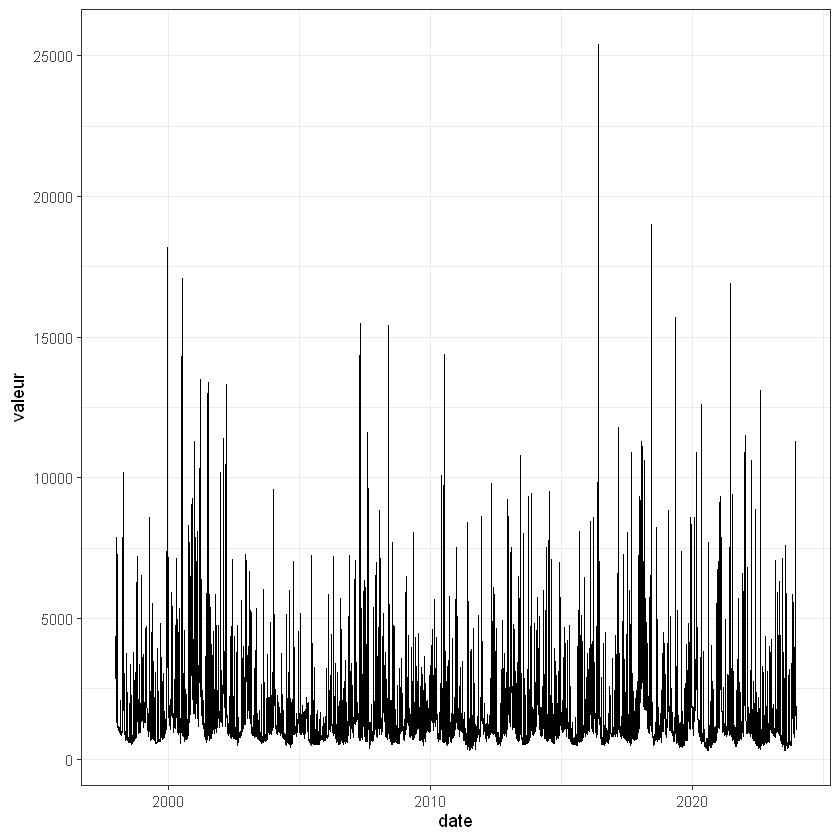

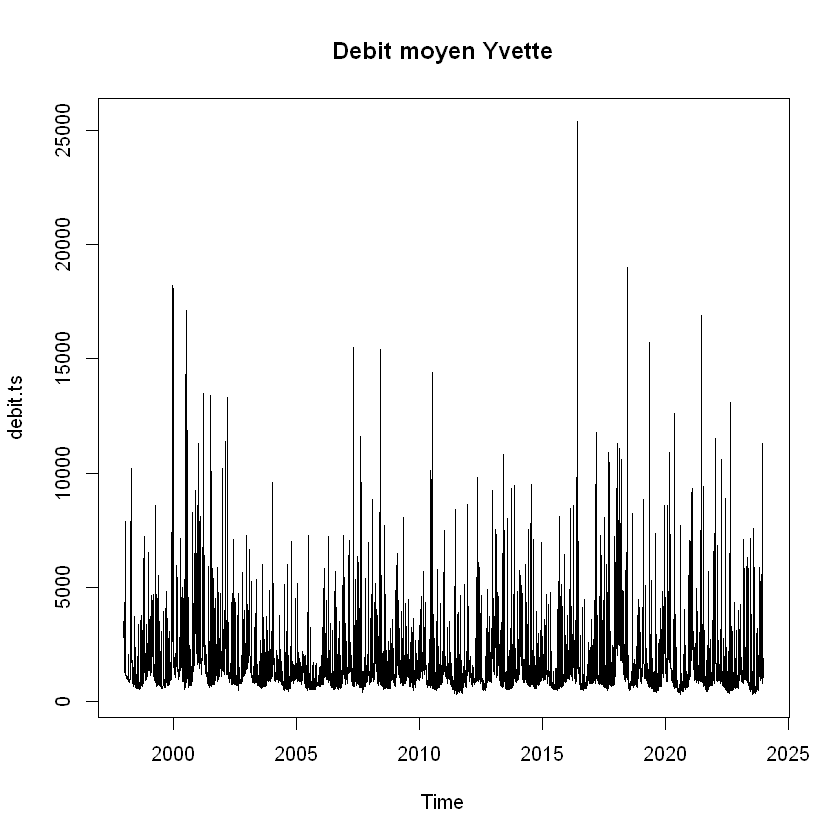

[1] 0

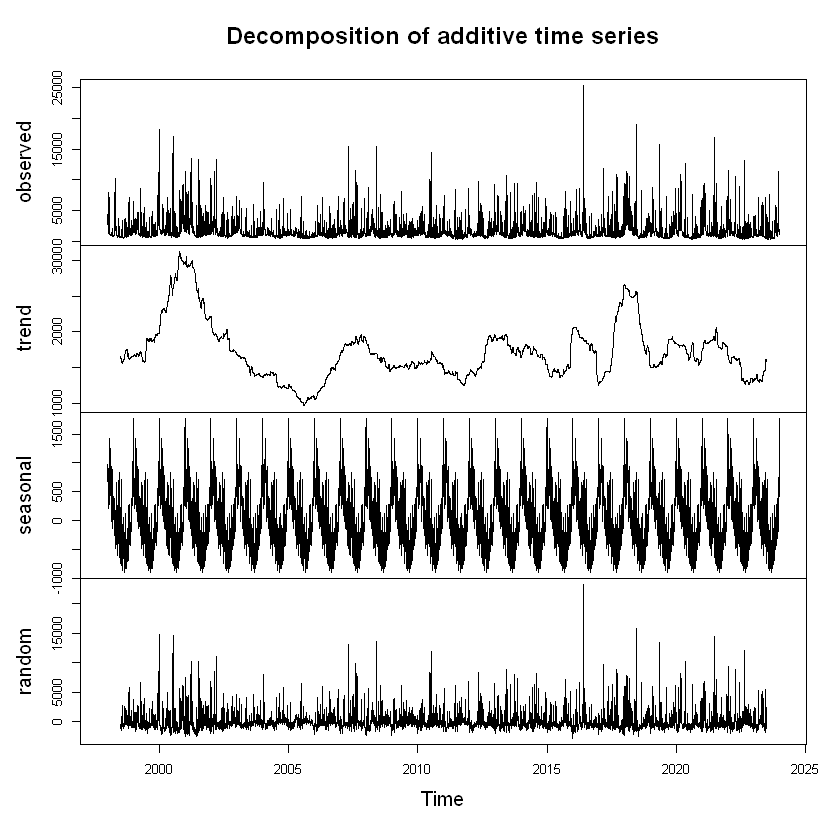

In [78]:
debitYvette <- read_excel("DebitYvette.xlsx") %>%
  rename(date = 'Date (TU)', valeur = 'Valeur (en l/s)') %>%
  mutate(date = as.Date(date)) %>%
  select(date, valeur)

# calendrier complet : les jours absents deviennent des NA explicites
calendrier  <- data.frame(date = seq(as.Date("1998-01-01"), as.Date("2023-12-31"), by = "day"))
debitComplet <- left_join(calendrier, debitYvette, by = "date")
sum(is.na(debitComplet$valeur))            # doit afficher 0

# supprimer les 29 février (plus robuste que la liste fev29 en caractères)
debitComplet <- debitComplet[format(debitComplet$date, "%m-%d") != "02-29", ]

par(bg = "white")
ggplot(debitComplet, aes(x = date, y = valeur)) + geom_line() + theme_bw()  # le vrai contrôle

debit <- debitComplet$valeur               # un vecteur, pas un tibble
na <- 25                                   # 26 années - 1, comme 72 = 73 - 1 chez la prof
debit.ts  <- ts(debit, start = c(1998, 1), frequency = 365)
plot(debit.ts,main='Debit moyen Yvette') # illustrer graphiquement la série 
debit.dec <- decompose(debit.ts)
plot(debit.dec) # illustrer graphiquement la décomposition
residus   <- debit.dec$random[(365+1):(365*na)]   # années 1999 à 2022
residus <- residus / 1000        # l/s -> m3/s
sum(is.na(residus))                        # doit afficher 0 si aucun na résiduel

Soit $Y_1, \dots Y_n$, les variables aléatoires qui modélisent les
résidus stationnaires journaliers de la série des températures. On
souhaite par la suite calculer le niveau de retour du record annuel
$z_N$ associé à la période de retour $N$ ans, c'est à dire la valeur
$z_N$ qui vérifie

$$ \mathbb{P}\Big( \max \{ Y_1,\dots, Y_{365} \} \leq z_N \Big) = 1- \frac{1}{N}.$$

## Approche GEV

1.  Construire des paquets de données de taille `tp` et calculer le
    nombre `P` de paquets par an. Construire la série de maxima par
    paquet.

In [79]:
#max annuel
tp = 365
np = floor(length(residus)/tp) # nombre total de paquets 
P  = 365/tp # nombre d'observation  

matResidus = matrix(residus,tp,np) # 
maxResidus = apply(matResidus,2,max,na.rm=TRUE)


2.  Illustrer graphiquement la série de maxima à l'aide d'une série
    chronologique et d'un histogramme.

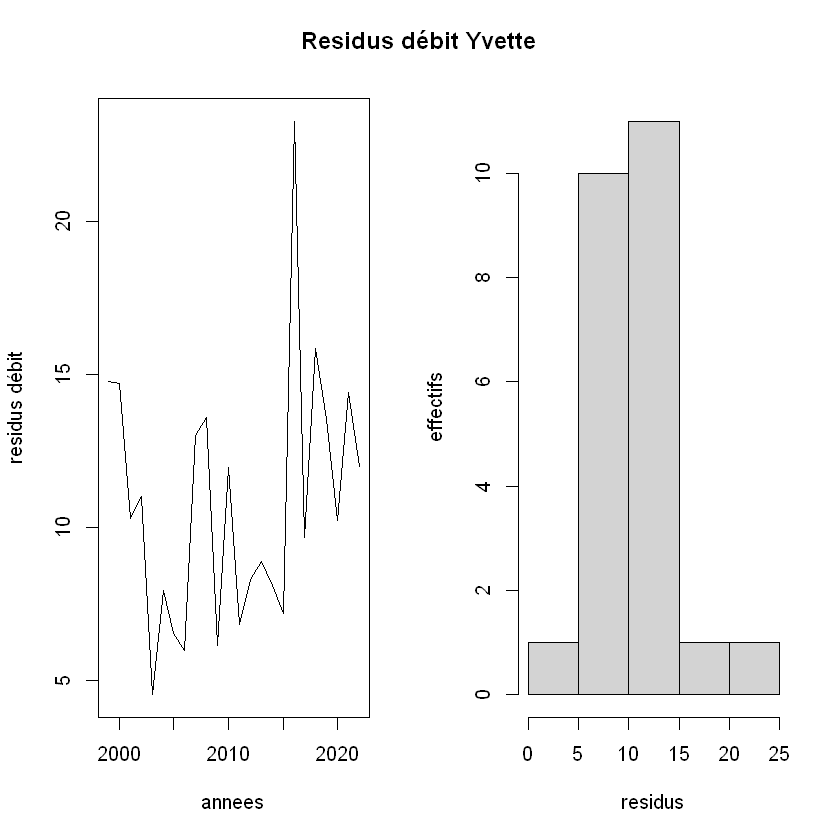

In [80]:
vecAn = 1999:2022
opar = par(mfrow = c(1,2))
par(bg = "white")
plot(vecAn,maxResidus,type='l',xlab='annees',ylab='residus débit')
hist(maxResidus,main='',xlab='residus',ylab='effectifs')
title(main = 'Residus débit Yvette',outer=TRUE,line=-2)
par(opar)

On remarque sur le graphe de gauche que les maxima annuels sont compris entre 5000 l/s et 25000 l/s. On a une année avec un maxima exceptionnellement haut (2015 on dirait).

Sur le graphe de droite, on a une distribution normalisée (avec une valeur extrême isolée) : les débits les plus frequentes sont autour de 9000 l/s.

3.  Ajuster une loi des extrêmes généralisée.


Call: fgev(x = maxResidus) 
Deviance: 132.1813 

Estimates
    loc    scale    shape  
8.88971  3.21561  0.01023  

Standard Errors
   loc   scale   shape  
0.7540  0.5602  0.1711  

Optimization Information
  Convergence: successful 
  Function Evaluations: 19 
  Gradient Evaluations: 6 


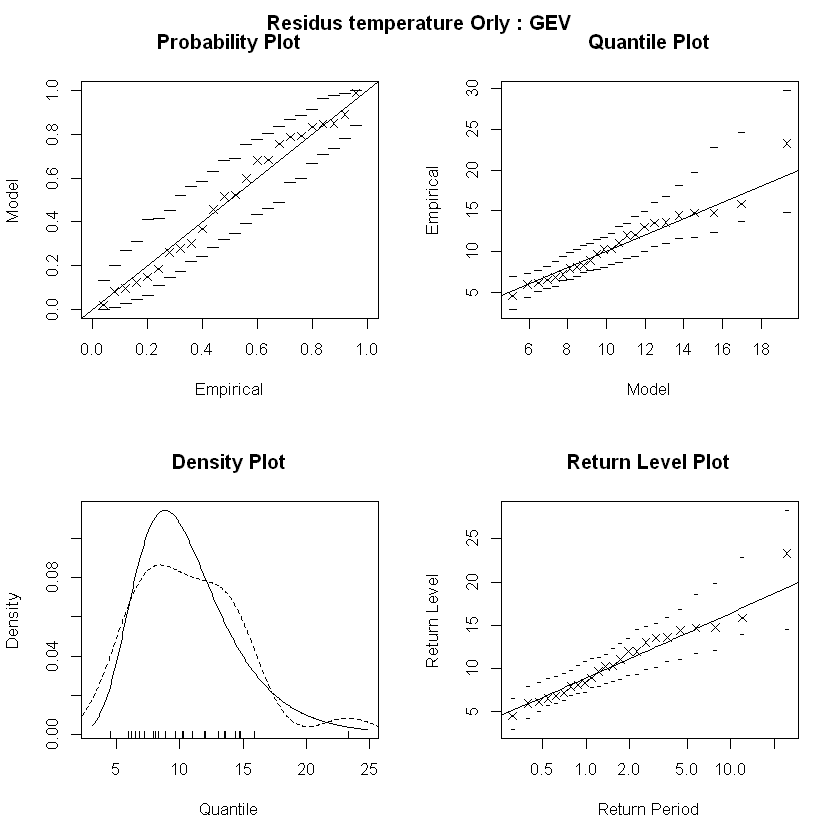

In [81]:
residus.fit=fgev(maxResidus) # utiliser fgev
residus.fit

opar = par(mfrow=c(2,2))
par(bg = "white")
plot(residus.fit) # graphes diagnostiques du modele 
title(main = 'Residus temperature Orly : GEV',outer=TRUE,line=-1.5)
par(opar)

Probability plot : 
Les points sont proches de la droite et ne s'en éloigne pas aux extrêmes. On observe toutefois une courbe dans le nuage de points.
=> Ajustement global cohérent

Quantile plot : 
Les points sont proches de la droite donc les quantiles observés sont cohérents avec ceux prédits sauf aux valeurs extrêmes.
=> Ajustement cohérent

Density plot : 
Les deux courbes sont relativement proches avec un léger écart au sommet. On a aussi des écarts sur les deux queues. Donc la concentration des valeurs ou la dispersion peut être mal représentée. 
Le léger écart dans la queue de droite peut signifier que les valeurs extrêmes sont être mal représentées.

Return level plot : 
Les points sont proches de la courbes donc le modèle prédit bien les valeurs extrêmes.Toutefois, on a une grande variabilité pour des périodes de retour plus longues.

4.  Calculer `q` le record historique de la série des températures et
    déduire la période de retour (en années) associée à ce niveau de
    retour annuel.

In [82]:
q = max(maxResidus, na.rm = TRUE)
p= pgev(q,loc = residus.fit$estimate["loc"],
        scale = residus.fit$estimate["scale"],
        shape = residus.fit$estimate["shape"],
        lower.tail = FALSE) # utiliser pgev 
Periode = 1/(p)
Periode ## 

shape 
79.88478

Periode = 24,7 ans

Donc on a une probabilité de dépassement annuelle de 4,05 %.

5.  Estimer les paramètres et en déduire un niveau de retour à 100 et
    200 ans.

[1] "profiling quantile"
[1] "profiling quantile"


,2.5 %,97.5 %
quantile,13.2587981,34.7798849
scale,2.1173692,4.3131502
shape,-0.3250336,0.3446564


,lower,upper
quantile,18.61552,60.31949


,2.5 %,97.5 %
quantile,12.0135720,40.7656573
scale,2.1174130,4.3138290
shape,-0.3259722,0.3464684


,lower,upper
quantile,19.91694,81.05101


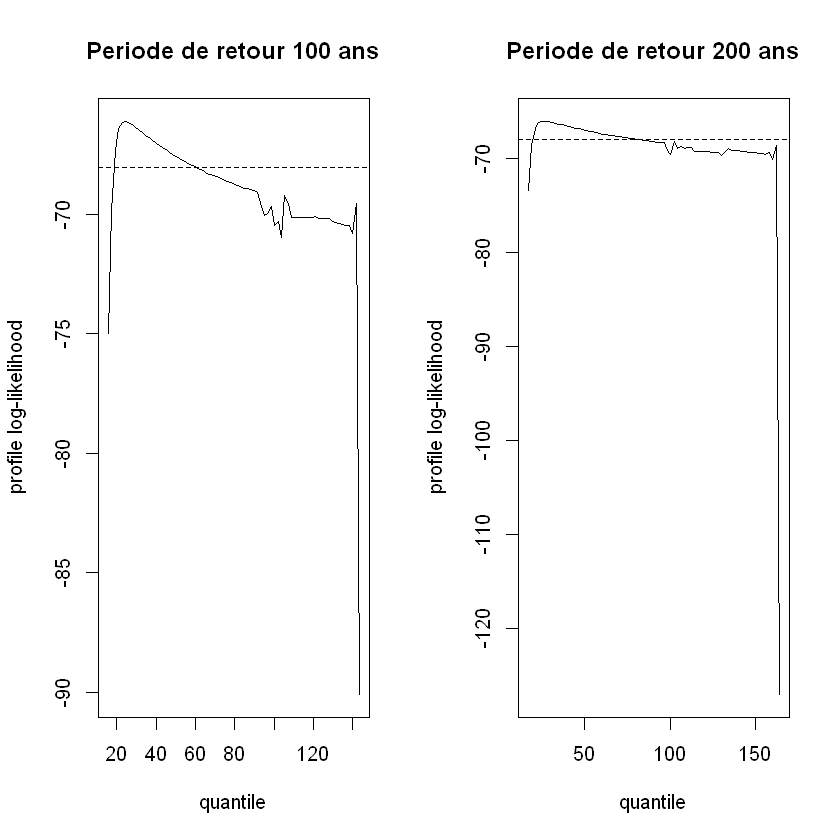

In [83]:
ProbDep2 = 1/200  # definir la proba qui nous interesse
ProbDep1 = 1/100   

residus.qfit1 = fgev(maxResidus,prob=ProbDep1)
residus.qdev.prof1 = profile(residus.qfit1,which="quantile")

residus.qfit2 = fgev(maxResidus,prob=ProbDep2)
residus.qdev.prof2 = profile(residus.qfit2,which="quantile")


opar = par(mfrow=c(1,2))
par(bg = "white")
residus.qPCI1 =plot(residus.qdev.prof1,
                                main='Periode de retour 100 ans')
residus.qPCI2 = plot(residus.qdev.prof2,
                                 main='Periode de retour 200 ans')

par(opar)

confint(residus.qfit1)

confint(residus.qdev.prof1)


confint(residus.qfit2)


confint(residus.qdev.prof2)

Que pouvez-vous conclure des intervalles de confiance ?

Pour residus.qfit1, on a shape [-0.25,0,32] donc le signe du paramètre de forme est incertain car l'intervalle contient zéro.

L'incertitude est importante car elle recoupe plusieurs centaines.

Courbe "Periode de retour de 100 ans" : 
On observe un plateau pour un quantile entre 20000 et 10000 puis une chute très brutale, le profil n'est pas usuel.

Courbe "Periode de retour de 200 ans" :
Le maximum est atteint pour un quantile entre 4000 et 17000 et décroit brutalement ensuite. 

### Taille de paquet differente

Soit $Y_1, \dots Y_n$, les variables aléatoires qui modélisent les
résidus stationnaires journaliers de la série des températures. On
souhaite par la suite calculer le niveau de retour journalier $z_N$
associé à la période de retour $N$ ans, c'est à dire la valeur $z_N$ qui
vérifie

$$ \mathbb{P}\Big( Y_1 \leq z_N \Big) = 1- \frac{1}{N*P}.$$
avec $P$ qui correspond au nombre d'observations journalières par an.

1.  Afficher la série chronologique et l'histogramme des données
    journalières.

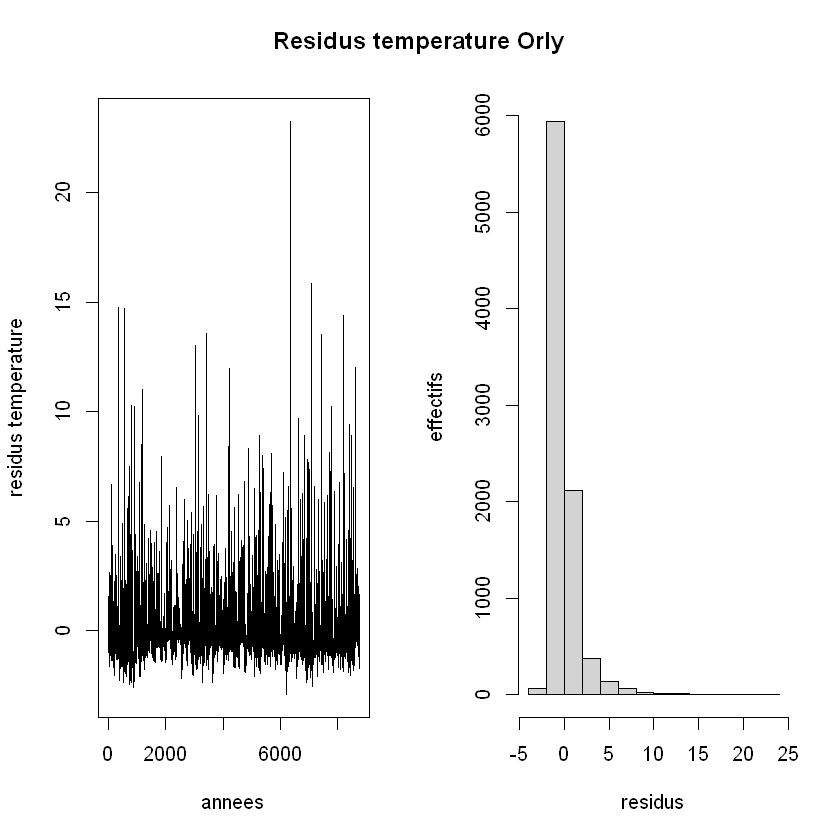

In [84]:
#max annuel
tp = 1
np = floor(length(residus)/tp)
P  = 365/tp # nombre d'observation  

matResidus = matrix(residus[1:np],tp,np) # 
maxResidus = apply(matResidus,2,max)

opar = par(mfrow = c(1,2))
par(bg = "white")
plot(maxResidus,type='l',xlab='annees',ylab='residus temperature')
hist(maxResidus,main='',xlab='residus',ylab='effectifs')

title(main = 'Residus temperature Orly',outer=TRUE,line=-2)

par (opar)

Les résidus ont une distribution normalisée autour de [-2000, 0] avec quelques valeurs extrêmes, surtout dans le positif vers [-10000;20000].

2.  Vérifier l'hypothèse des observations iid

[1] 1.0000000 0.5547945 0.3550228 0.2865297 0.2408676 0.2054795 0.1815068
 [8] 0.1621005 0.1392694 0.1302857 0.1155606 0.1098398

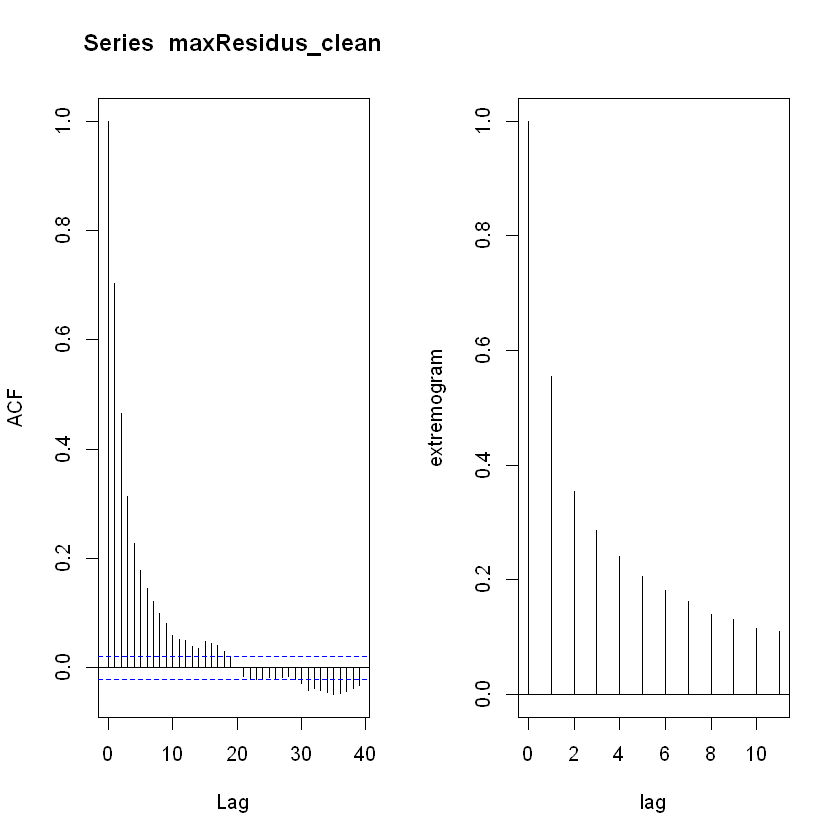

In [85]:
maxResidus_clean <- maxResidus[is.finite(maxResidus)]

par(mfrow = c(1, 2))
par(bg = "white")

acf(maxResidus_clean)

extremogram1(maxResidus_clean, quant = 0.9, maxlag = 12,type = 1)

Pour les deux graphes, pour lag = 1, on a une autocorrélation forte (autant pour l'ensemble des valeurs que pour uniquement les valeurs extrêmes) qui diminue progressivement mais qui reste quand même importante. Donc on a une dépendance temporelle forte des valeurs entre elles, et des valeurs extrêmes entre elles.

**On remarque que si cette hypothèse d'indépendance n'est par vérifiée
alors il faudra calculer l'indice de clustering** $\theta$ de la série
afin de conclure.

En effet,

$$\begin{align*}
 \mathbb{P}\Big( Y_1 \leq z_N \Big) 
  &\approx \mathbb{P}\Big( \max \{ Y_1,\dots, Y_{m} \} \leq z_N \Big)^{1/(\theta m)}
 \end{align*}$$
avec $m$ une taille de paquet quelconque.

Donc, il suffit de trouver $z_N$ tel que

$$\mathbb{P}\Big( \max \{ Y_1,\dots, Y_{m} \} \leq z_N \Big)^{1/(\theta m)} = 1- \frac{1}{N*P}.$$
avec $P$ qui correspond au nombre d'observations du maxima par an.

3.  Utiliser une taille de paquet `tp` = 5 (et ensuite `tp` = 73) et
    calculer les maxima par parquets. Afficher la série chronologique et
    l'histogramme des la série de records par paquets.

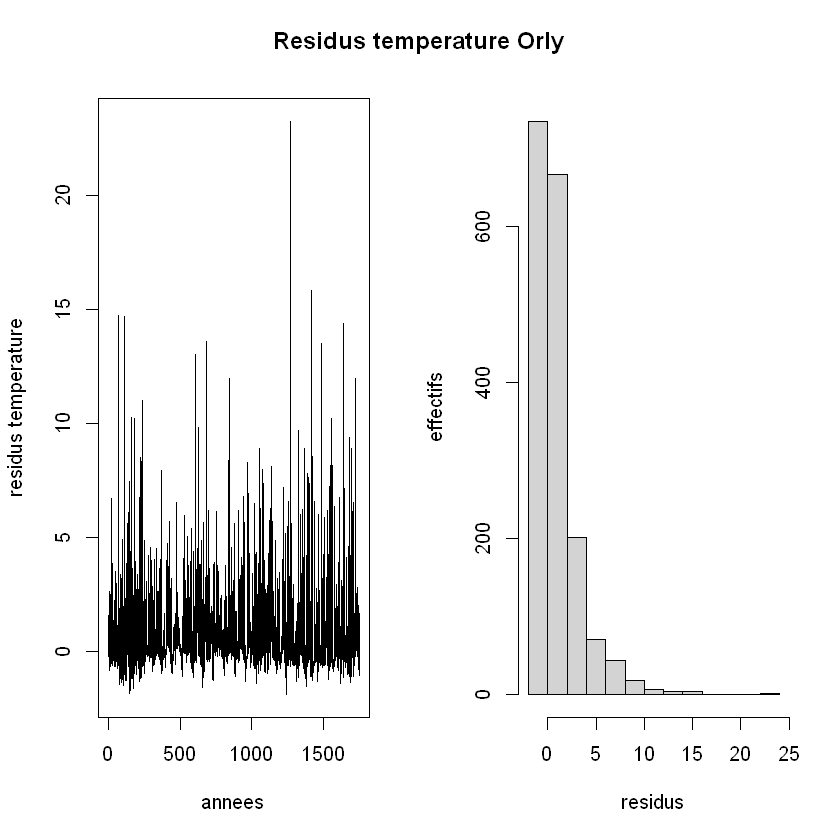

In [86]:
#max annuel
tp = 5
np = floor(length(residus)/tp)
P  = 365/tp # nombre d'observation  

matResidus = matrix(residus[1:(np*tp)],tp,np) # 
maxResidus = apply(matResidus,2,max)

opar = par(mfrow = c(1,2))
par(bg = "white")
plot(maxResidus,type='l',xlab='annees',ylab='residus temperature')
hist(maxResidus,main='',xlab='residus',ylab='effectifs')

title(main = 'Residus temperature Orly',outer=TRUE,line=-2)

Les paquets de 5 valeurs sont distribués normalement autour de -3000 et 10000.

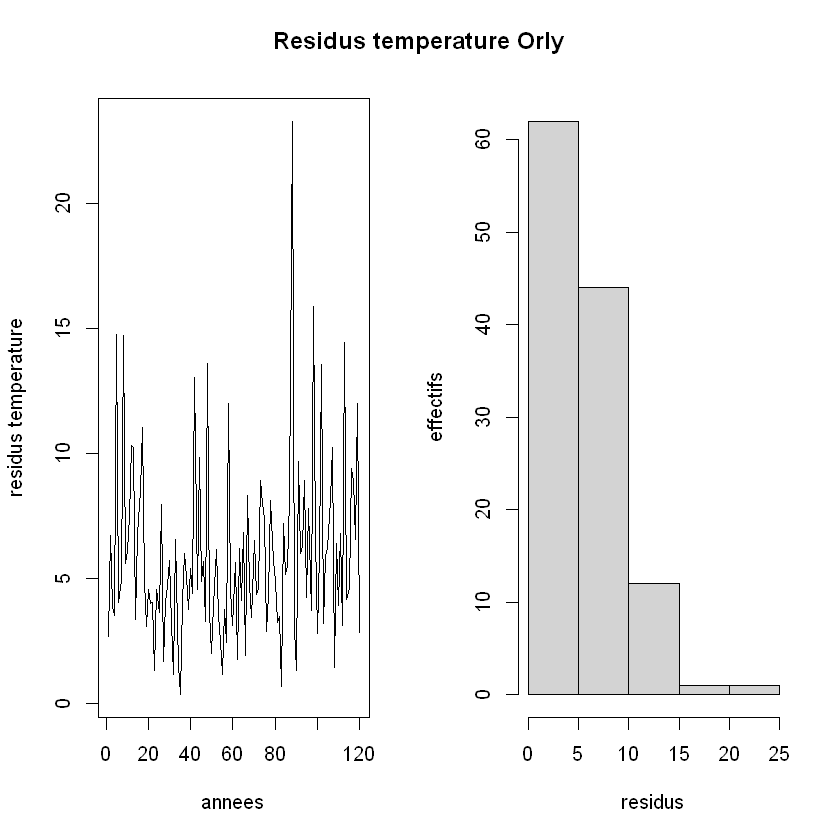

In [87]:
#max annuel
tp = 73
np = floor(length(residus)/tp)
P  = 365/tp # nombre d'observation  

matResidus = matrix(residus[1:(np*tp)],tp,np) # 
maxResidus = apply(matResidus,2,max)

opar = par(mfrow = c(1,2))
par(bg = "white")
plot(maxResidus,type='l',xlab='annees',ylab='residus temperature')
hist(maxResidus,main='',xlab='residus',ylab='effectifs')

title(main = 'Residus temperature Orly',outer=TRUE,line=-2)
par(opar)

Les paquets de 39 valeurs sont distribués autour de 0 et 16000.

4.  Vérifier que les maxima par paquets sont indépendants.

[1] 1.00000000 0.00000000 0.00000000 0.09090909 0.18181818 0.09090909
 [7] 0.18181818 0.09090909 0.00000000 0.10000000 0.20000000 0.10000000

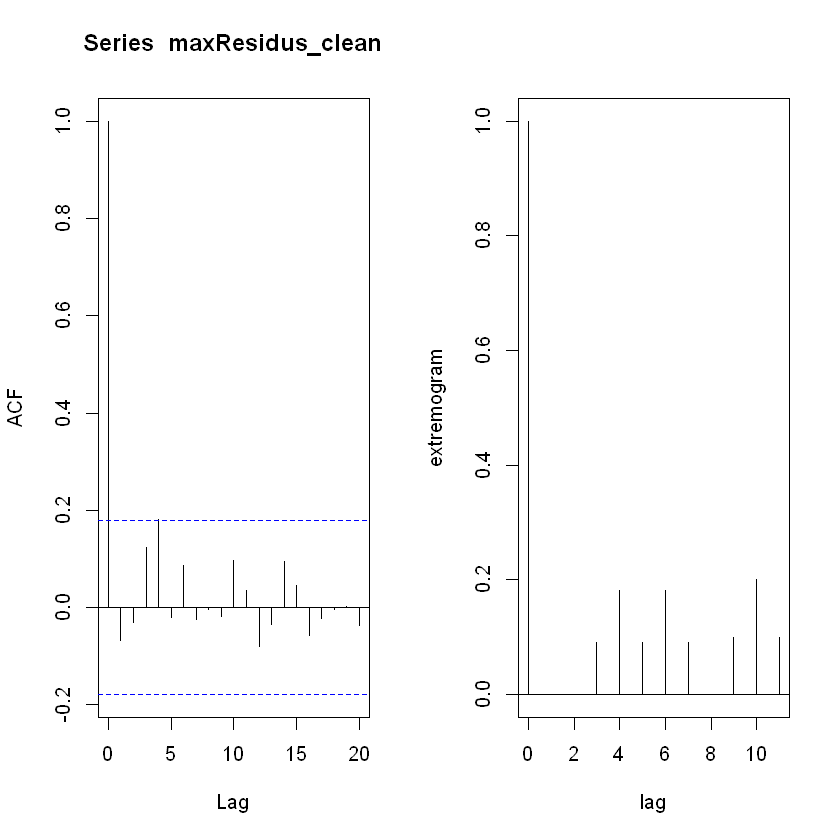

In [88]:
maxResidus_clean <- maxResidus[is.finite(maxResidus)]

par(mfrow = c(1, 2))
par(bg = "white")

acf(maxResidus_clean)

extremogram1(maxResidus_clean, quant = 0.9, maxlag = 12,type = 1)
par(opar)

Comme le graphe d'avant, on a une autocorrélation forte pour lag = 1, mais, cette fois-ci, elle décroit très rapidement autant pour l'ensemble des valeurs que pour les valeurs extrêmes (même si c'est moins flagrant pour ces valeurs extrêmes). Donc les valeurs, et les valeurs extrêmes, sont plutôt indépendantes temporrellement ici. 

5.  Ajuster une loi des extrêmes généralisée.


Call: fgev(x = maxResidus) 
Deviance: 607.5253 

Estimates
   loc   scale   shape  
4.1764  2.4552  0.0956  

Standard Errors
    loc    scale    shape  
0.25188  0.18881  0.06764  

Optimization Information
  Convergence: successful 
  Function Evaluations: 17 
  Gradient Evaluations: 8 


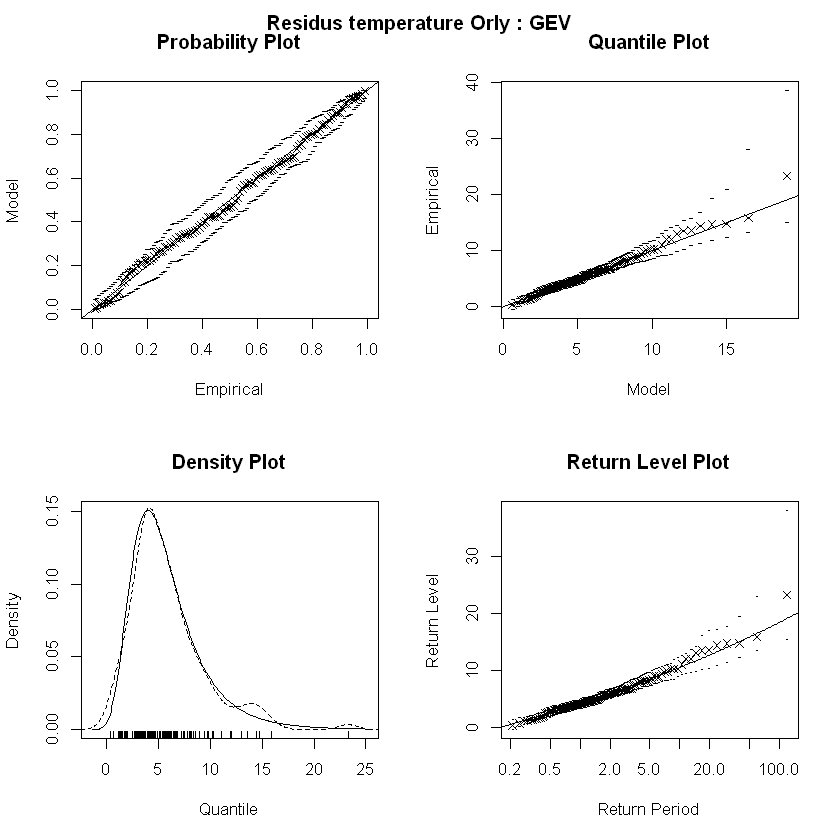

In [89]:
# Approche GEV
#=============
residus.fit=fgev(maxResidus)
residus.fit

opar = par(mfrow=c(2,2))
par(bg = "white")
plot(residus.fit)
title(main = 'Residus temperature Orly : GEV',outer=TRUE,line=-1.5)

par(opar)

Probability plot : 
Les points sont proches de la droite et ne s'en éloigne pas aux extrêmes. On observe pas de courbe dans le nuage de points.
=> Ajustement global cohérent

Quantile plot : 
Les points sont proches de la droite donc les quantiles observés sont cohérents avec ceux prédits. Même si on a toujours un écart aux extrêmes.
=> Ajustement cohérent

Density plot : 
Les deux courbes sont relativement proches avec un léger écart au sommet donc la concentration des valeurs ou la dispersion est bien représentée. 
Même dans la queue de droite, les valeurs extrêmes sont plutôt proches du modèles donc elles sont bien représentées.

Return level plot : 
Les points sont proches de la courbes donc le modèle prédit plutôt bien les valeurs extrêmes.

6.  Estimer les paramètres et en déduire un niveau de retour à 100 et
    200 ans lorsque l'indice extremal de résidus vaut $\theta = 0.5$. On
    calculera ce dernier à continuation.

In [90]:
theta = 0.5
P = 365

ProbDep1 = (1/theta) * 1/(100*P) # definir la proba qui nous interesse
ProbDep2 = (1/theta) * 1/(200*P)

# Ajustements GEV sans calcul de la matrice de covariance
residus.qfit1 = fgev(maxResidus, prob = ProbDep1, std.err = FALSE)

residus.qfit2 = fgev(maxResidus,prob = ProbDep2, std.err = FALSE)


# Vérification de la convergence
residus.qfit1$convergence
residus.qfit2$convergence

[1] "successful"

[1] "successful"

[1] "profiling quantile"
[1] "profiling quantile"


,2.5 %,97.5 %
quantile,14.80788313,41.5849885
scale,2.08389472,2.8258861
shape,-0.05251906,0.2437135


,lower,upper
quantile,20.37546,49.02034


,2.5 %,97.5 %
quantile,11.6066694,51.545352
scale,2.0775082,2.822063
shape,-0.0804922,0.272273


,lower,upper
quantile,21.93212,58.83817


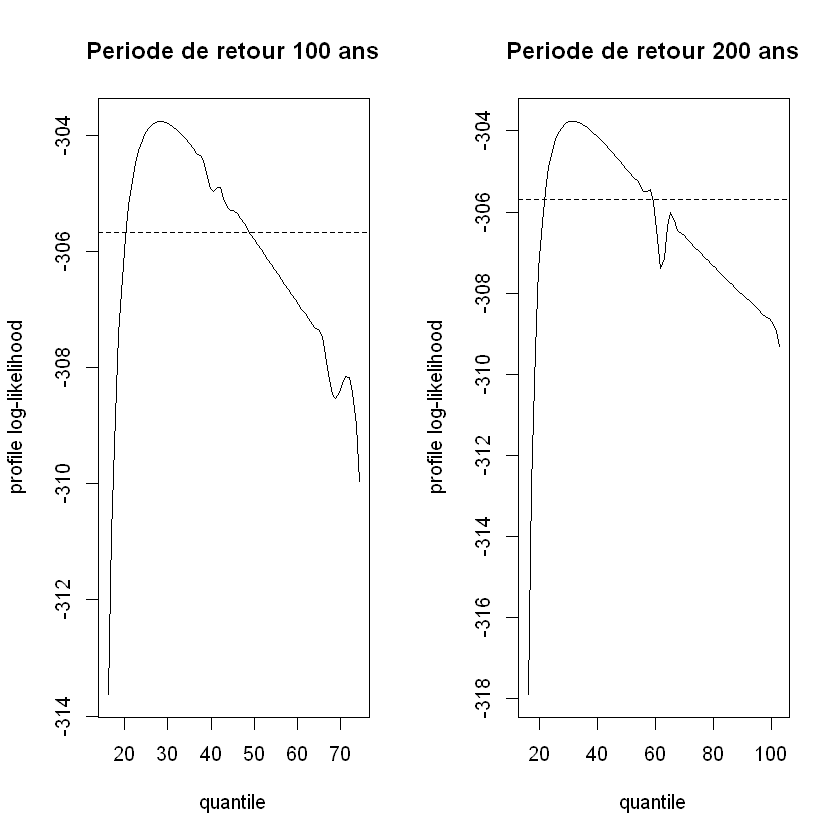

In [101]:
theta = 0.5
P = 365
tp = 73

ProbDep1 = theta * tp / (100 * P)  # definir la proba qui nous interesse
ProbDep2 = theta * tp / (200 * P)

residus.qfit1 = fgev(maxResidus,prob=ProbDep1)
residus.qdev.prof1 = profile(residus.qfit1,which="quantile")

residus.qfit2 = fgev(maxResidus,prob=ProbDep2)
residus.qdev.prof2 = profile(residus.qfit2,which="quantile")

opar = par(mfrow=c(1,2))
par(bg = "white")
residus.qPCI1 =plot(residus.qdev.prof1,
                                main='Periode de retour 100 ans')
residus.qPCI2 = plot(residus.qdev.prof2,
                                 main='Periode de retour 200 ans')

par(opar)

confint(residus.qfit1)

confint(residus.qdev.prof1)

confint(residus.qfit2)

confint(residus.qdev.prof2)

## Approche POT

On propose à continuation une deuxième approche pour calculer le niveau
de retour journalier $z_N$ associé à la période de retour 100 ans et 200
ans.
$$ \mathbb{P}\Big( Y_1 \leq z_N \Big) = 1- \frac{1}{N*P}.$$

On implémente à continuation la méthode POT.

1.  Déterminer le seuil et visualiser les dépassements.

90%      95%      98%      99% 
1.387881 2.854089 4.990896 6.641531

[1] 264

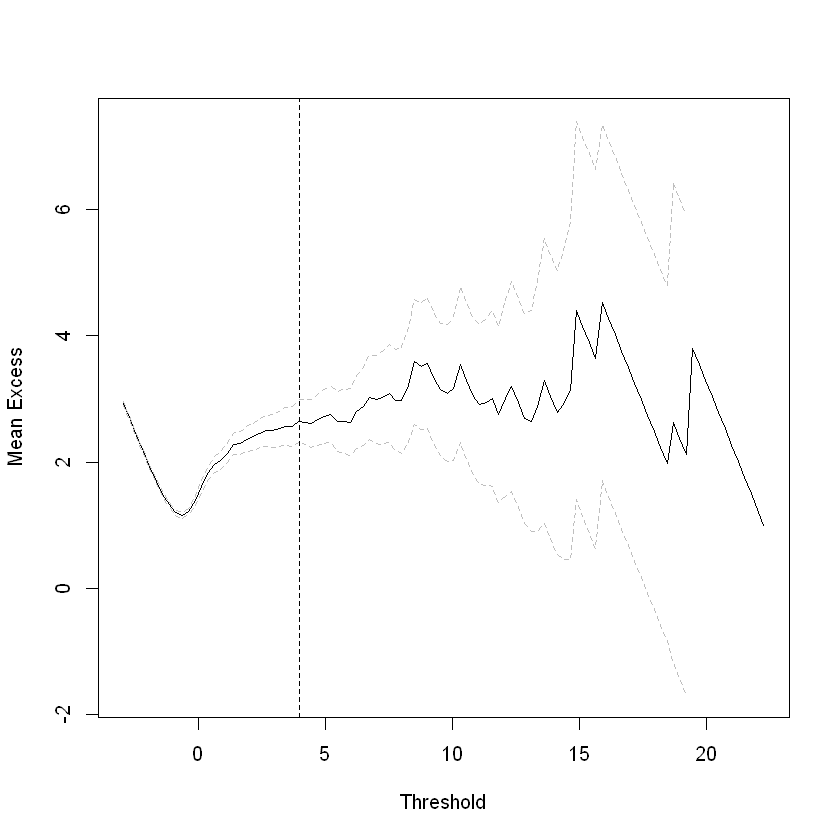

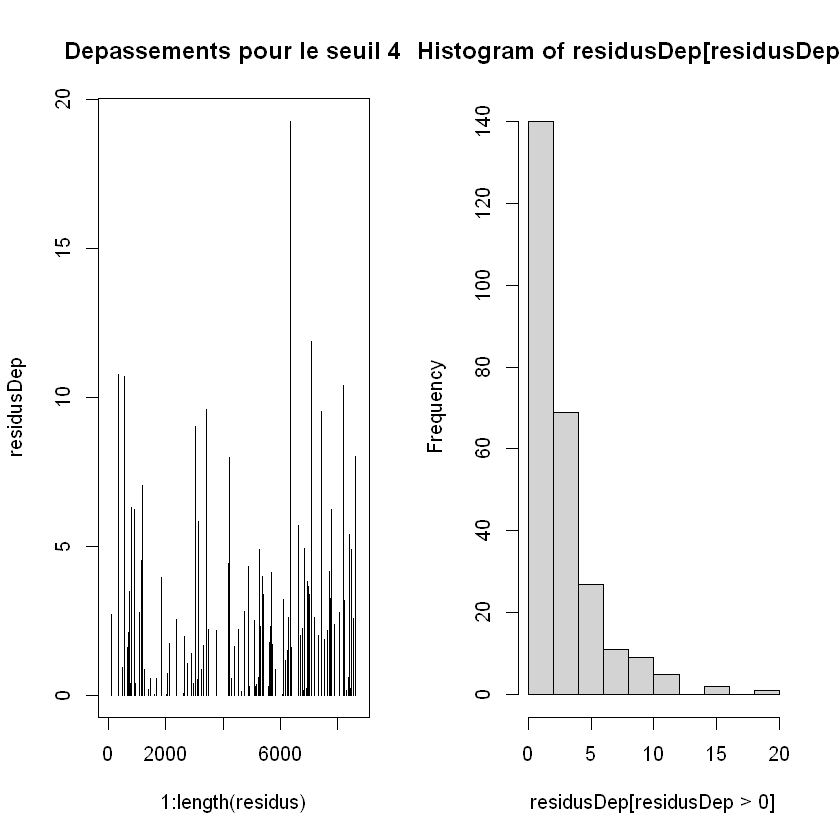

In [92]:
# Approche GPD
#=============
par(bg = "white")
mrlplot(residus)
quantile(residus, c(.90, .95, .98, .99))   # pour se repérer
seuil = 4
abline(v=seuil,lty=2)
sum(residus > seuil)

opar = par(mfrow = c(1,2))
residusDep = residus-seuil
residusDep[residusDep<0]=NA
plot(1:length(residus),residusDep,type='h',
     main=paste('Depassements pour le seuil',seuil))
hist(residusDep[residusDep>0])
par(opar)

On voit que la pente de la courbe ralentie à partir de 0 et que les valeurs deviennent irrégulire après de 60. Donc on peut prendre un seuil entre 30 et 60.

Lorsqu'on visualise les dépassements, on remarque que la majorité des résidu-seuil est comprise entre 0 et 5. Plus résidu-seuil augmente, plus la fréquence de dépassement du seuil diminue.On observe toutefois quelques valeurs extrêmes avec des résidus-seuil > 40.

2.  Ajuster aux dépassement de seuil une loi GPD. Utiliser des
    graphiques diagnostiques pour évaluer la qualité de l'ajustement
    obtenu.


Call: fpot(x = residus, threshold = seuil, npp = 365) 
Deviance: 1036.542 

Threshold: 4 
Number Above: 264 
Proportion Above: 0.0301 

Estimates
  scale    shape  
2.43776  0.07207  

Standard Errors
  scale    shape  
0.22071  0.06655  

Optimization Information
  Convergence: successful 
  Function Evaluations: 17 
  Gradient Evaluations: 6 


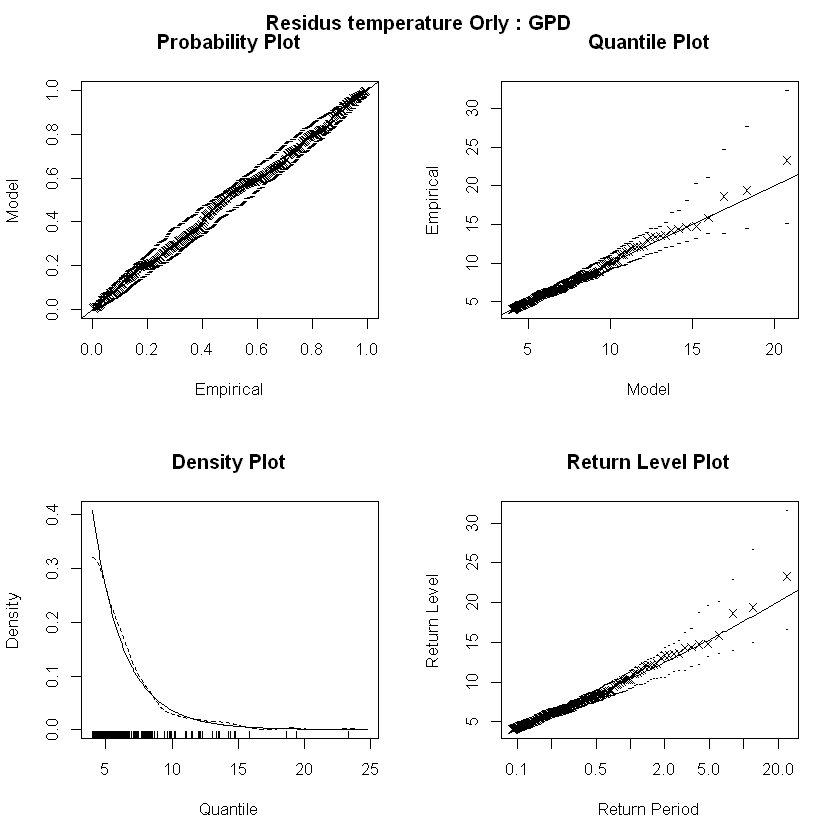

In [93]:
residus.gpd=fpot(residus,seuil,npp=365) 
residus.gpd
opar = par(mfrow=c(2,2))
par(bg="white")
plot(residus.gpd)
title(main = 'Residus temperature Orly : GPD',outer=TRUE,line=-1.5)
par(opar)

Probability plot : 
Les points sont proches de la droite et ne s'en éloigne pas aux extrêmes. On observe pas de courbe dans le nuage de points.
=> Ajustement global cohérent

Quantile plot : 
Les points sont proches de la droite donc les quantiles observés sont cohérents avec ceux prédits.
=> Ajustement cohérent

Density plot : 
Les deux courbes sont proches et se chevauchent presque. 
Même dans la queue de droite, les valeurs extrêmes sont proches du modèles donc elles sont bien représentées.

Return level plot : 
Les points sont proches de la courbes donc le modèle prédit bien les valeurs extrêmes.

3.  Estimer les paramètres et en déduire un niveau de retour à 100 et
    200 ans.

[1] "profiling rlevel"
[1] "profiling rlevel"


,2.5 %,97.5 %
rlevel,17.43842883,34.9712308
shape,-0.05837538,0.2024759


,lower,upper
rlevel,20.34715,40.7758


,2.5 %,97.5 %
rlevel,17.90392788,40.2586851
shape,-0.05837856,0.2026191


,lower,upper
rlevel,21.77044,48.4037


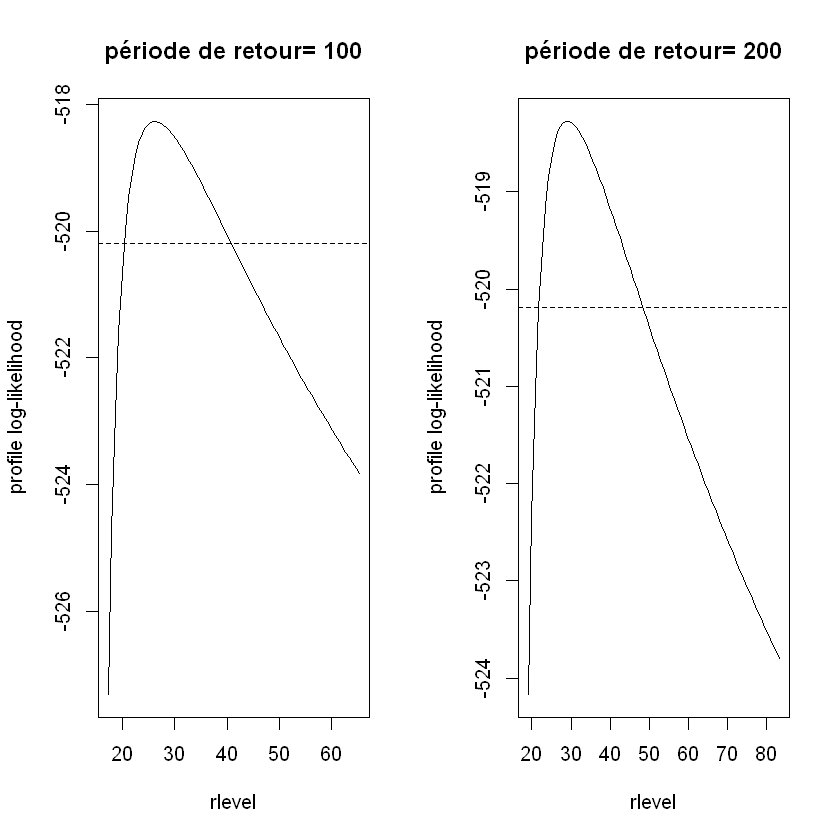

In [94]:
Pretour1 = 100
Pretour2 = 200
residus.q1 = fpot(residus,seuil,npp=365,mper=Pretour1)
residus.dev.qprof1 = profile(residus.q1,which='rlevel') 

residus.q2 = fpot(residus,seuil,npp=365,mper=Pretour2) 
residus.dev.qprof2 = profile(residus.q2,which='rlevel')

opar = par(mfrow=c(1,2))
par(bg="white")
residus.dev.qPIC1 = plot(residus.dev.qprof1,main=paste('période de retour=',Pretour1))
residus.dev.qPIC2 = plot(residus.dev.qprof2,main=paste('période de retour=',Pretour2))

par(opar)

confint(residus.q1)

confint(residus.dev.qprof1)

confint(residus.q2)

confint(residus.dev.qprof2)

Les intervalles [lowest, upper] sont relativement petits et se chevauchent entre qfit1 et qfit2. Les shape (paramètre de forme) de qfit1 et qfit2 sont négatifs donc la distribution ajustée appartient au domaine de Weibull.



 Data span  23.98084 years 
Setting up parameter model design matrices.
Parameter model design matrices set up.
Using Lmoments estimates as initial estimates.  Initial value = 518.2711 
Initial estimates are:
     scale      shape 
2.44100581 0.07070958 
Beginning estimation procedure.
initial  value 518.271080 
final  value 518.270870 
converged
Time difference of 0.01338792 secs


[1] 29.07905


 Preparing to calculate  95 % CI for  200-year return level 

 Model is   fixed 

 Using Profile Likelihood Method.

 Calculating profile likelihood.  This may take a few moments.

 Profile likelihood has been calculated.  Now, trying to find where it crosses the critical value =  -520.1916 


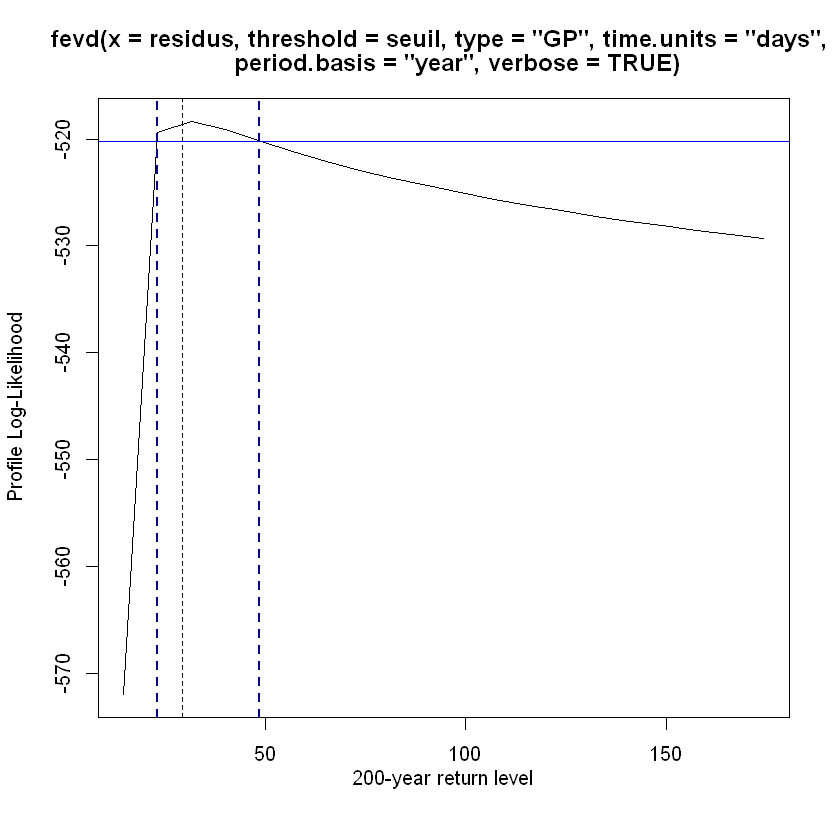

In [95]:
# Une alternative avec le package extRemes 
par(bg="white")
library(extRemes)
fit <- fevd(residus,
              threshold = seuil, 
              time.units = "days",
              period.basis = "year",
              type = "GP", 
              verbose = TRUE)

rl <- as.numeric(return.level(fit, return.period = Pretour2))
rl                                   # niveau de retour à 200 ans estimé, en m3/s

ci_proflik <- ci(fit, type = "return.level", method = "proflik", return.period = Pretour2, verbose = T, xrange = c(0.5 * rl, 6 * rl)) #centrer la plage sur le niveau de retour estimé


4.  Vérifier l'hypothèse des observations iid

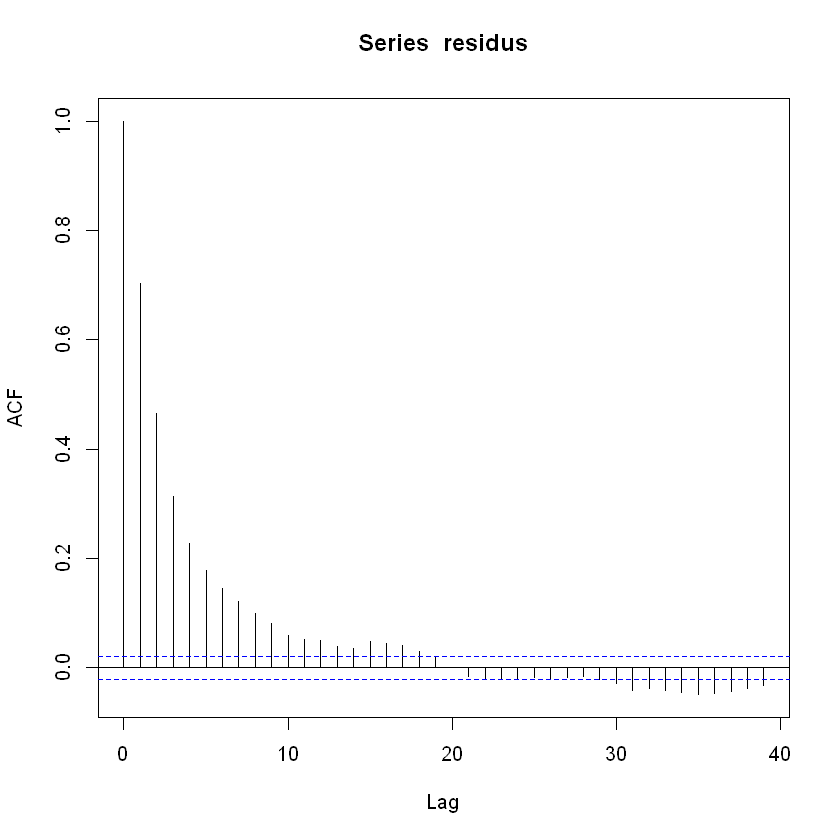

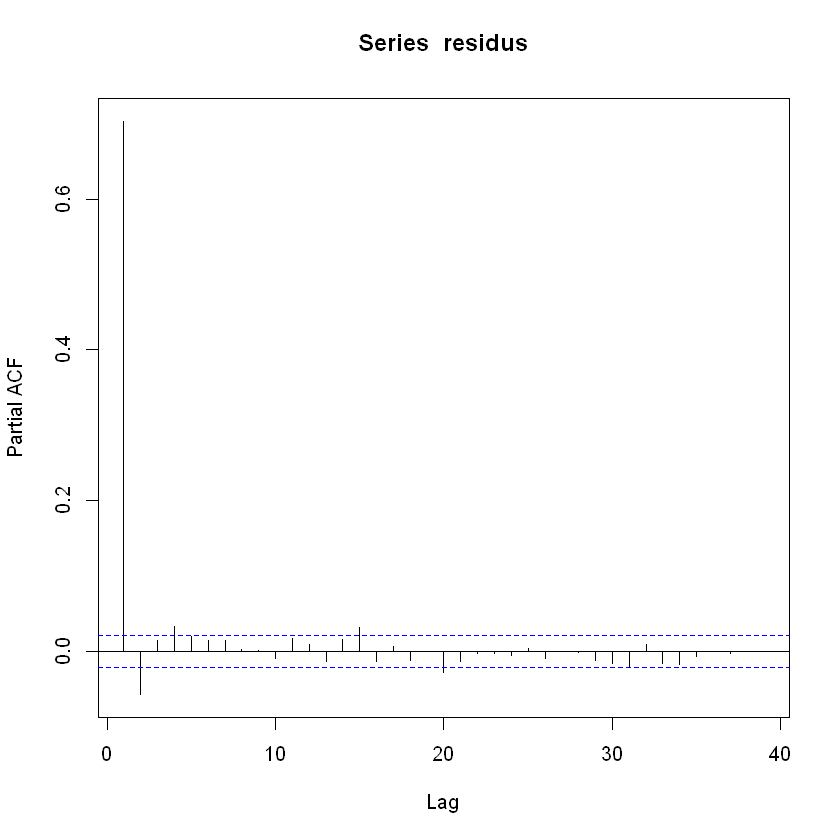

[1] 1.00000000 0.50000000 0.30681818 0.18939394 0.12121212 0.08333333
 [7] 0.08333333 0.09469697 0.08333333 0.06818182 0.05681818 0.06060606
[13] 0.05681818 0.05681818 0.05681818 0.06818182 0.06818182 0.05681818
[19] 0.06060606 0.04924242 0.03787879 0.03787879 0.03409091 0.03409091
[25] 0.04545455 0.04545455 0.04545455 0.04545455 0.03787879 0.04166667

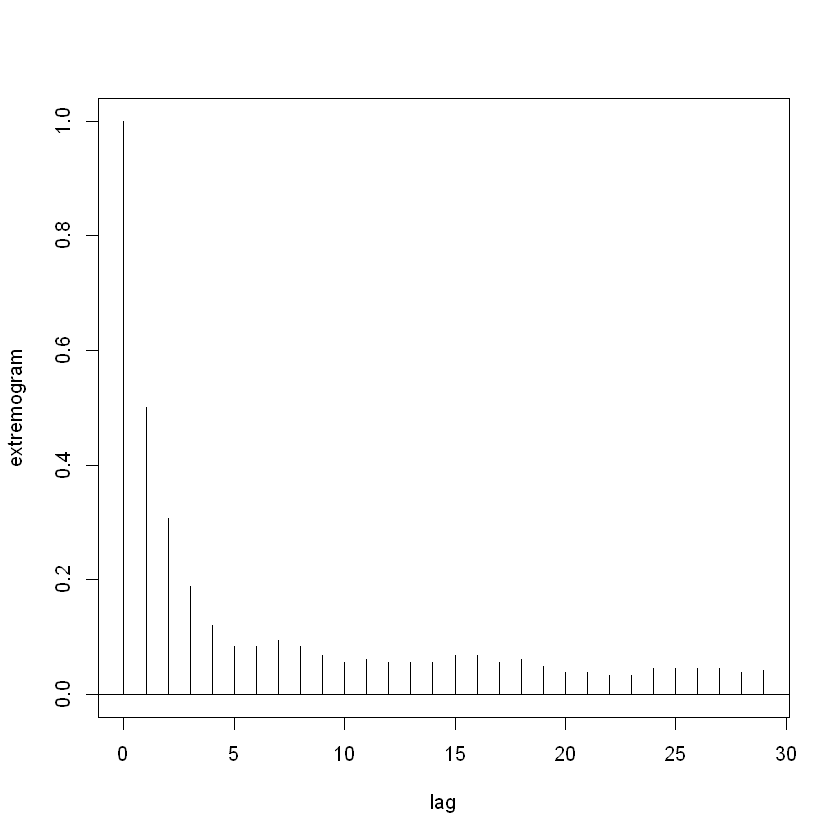

In [96]:
par(mfrow=c(1,1))
par(bg="white")
acf(residus)
pacf(residus)
extremogram1(residus,quant = sum(residus<=seuil)/length(residus), maxlag=30 , type = 1)

Quand on regarde l'extremogramme, on voit que pour lag = 1, l'autocorrélation est forte puis diminue brusquement ensuite. Donc les variables sont indépendantes.

5.  Calculer l'indice extremal de clustering

In [97]:

# Approche clusters
#==================
separ = 5
clusters   = clusters(residus,seuil,r=separ)
residus.q1 = fpot(residus,seuil,npp=365, r=separ, cmax=TRUE)
theta = length(clusters)/sum(residus>seuil)
theta 

[1] 0.4280303

On obtient teta = 0,50
=> On a un regroupement notable, les événements tendent à se reproduire en épisodes plutôt que de manière isolée.

6.  Ré-estimer les paramètres et les niveaux de retour à 100 et 200 ans
    et comparer avec l'approche indépendante.


 Data span  0.3066393 years 
Setting up parameter model design matrices.
Parameter model design matrices set up.
Using Lmoments estimates as initial estimates.  Initial value = 129.7347 
Initial estimates are:
     scale      shape 
 2.9555674 -0.1494303 
Beginning estimation procedure.
initial  value 129.734744 
final  value 129.730908 
converged
Time difference of 0.006605864 secs

 Preparing to calculate  95 % CI for  200-year return level 

 Model is   fixed 

 Using Profile Likelihood Method.

 Calculating profile likelihood.  This may take a few moments.

 Profile likelihood has been calculated.  Now, trying to find where it crosses the critical value =  -131.6516 


fevd(x = resid_clustr, threshold = seuil, type = "GP", time.units = "days", 
    period.basis = "year", verbose = TRUE)

[1] "Profile Likelihood"

[1] "200-year return level: 20.263"

[1] "95% Confidence Interval: (15.9974, 66.4014)"


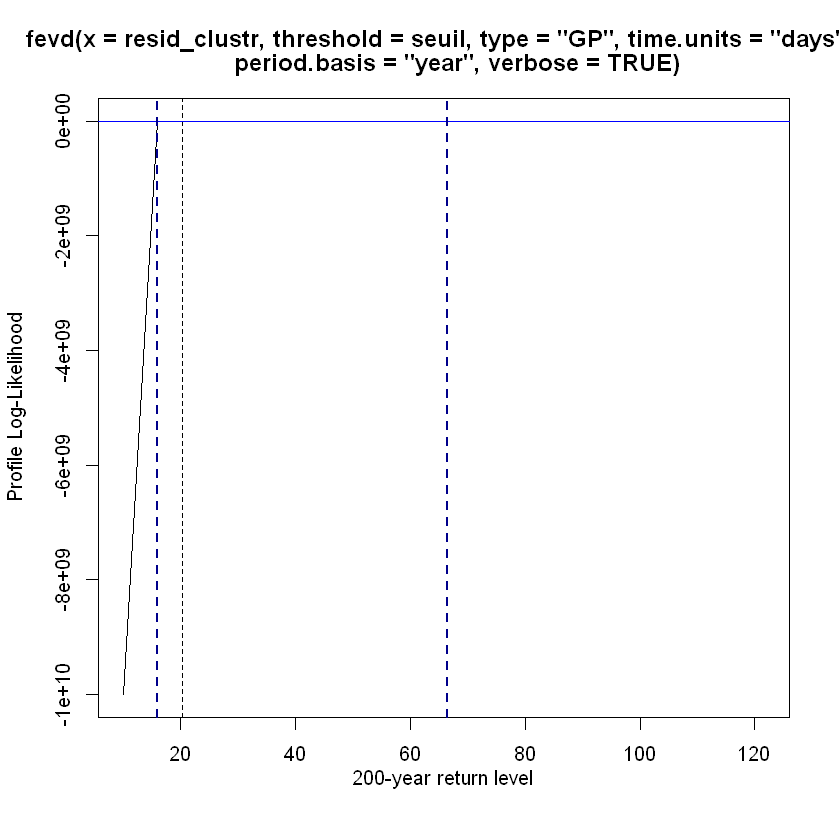

In [98]:
## approche GPD 
set.seed(12)
par(bg="white")
resid_clustr <- sapply(1:length(clusters), function(k) sample(clusters[[k]], 1) ) # sample clusters 
fit <- fevd(resid_clustr,
              threshold = seuil, 
              time.units = "days",
              period.basis = "year",
              type = "GP", 
              verbose = TRUE)

rl2 <- as.numeric(return.level(fit, return.period = Pretour2))   # avec le fit refait sur resid_clustr

ci_proflik <- ci(fit, type = "return.level", method = "proflik", return.period = Pretour2, verbose = T, xrange = c(0.5 * rl2, 6 * rl2))

ci_proflik
